# PRCL-0027 — Spare Parts Inventory Forecasting

## Project Overview

This project focuses on analyzing spare parts usage and developing a machine learning-based forecasting solution for NewX Services.

The project aims to understand historical spare parts consumption patterns and predict future demand to help service centres maintain appropriate inventory levels.

Effective inventory management is important because excess inventory increases storage and maintenance costs, while insufficient inventory can lead to spare parts shortages and service delays.

This project involves data exploration, data cleaning, exploratory data analysis, feature engineering, time-series analysis, machine learning model development, and future demand forecasting.

## Project Objectives

### Task 1 — Data Analysis
Perform exploratory data analysis to understand historical spare parts transactions, vehicle models, service dates, and spare parts usage patterns.

### Task 2 — Data Preprocessing
Clean and prepare the dataset by handling missing values, duplicate records, inconsistent values, and date-related information.

### Task 3 — Demand Analysis
Identify frequently used spare parts, monthly demand patterns, and spare parts consumption trends.

### Task 4 — Predictive Modeling
Develop suitable forecasting models to estimate future spare parts demand based on historical transaction data.

### Task 5 — Model Evaluation
Compare forecasting models using appropriate evaluation metrics and select a suitable model.

### Task 6 — Inventory Planning
Use the forecasted demand to provide inventory planning recommendations that support Just-in-Time (JIT) inventory management.

### Challenges Report
Document the challenges faced during data preparation, demand identification, feature engineering, and forecasting, along with the techniques used to address them.

In [1]:
# Importing Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
print("Python environment is ready.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Python environment is ready.
Pandas version: 2.3.3
NumPy version: 2.3.5


## Dataset Information

The dataset contains historical service and spare parts transaction records collected from NewX Services.

The dataset consists of approximately 28,484 records and 7 attributes.

### Important Attributes

- Invoice Date: Date on which the invoice was generated.
- Job Card Date: Date on which the service job card was created.
- Business Partner Name: Name of the business partner or customer.
- Vehicle No.: Unique vehicle registration identifier.
- Vehicle Model: Model of the vehicle receiving service.
- Current KM Reading: Current kilometre reading of the vehicle.
- INVOICE LINE TEXT: Description of the spare part or service item recorded in the invoice.

### Dataset Objective

The dataset will be explored to identify historical spare parts consumption patterns and prepare suitable time-based demand data for forecasting.

The availability of a reliable demand quantity and identifiable spare parts will be verified during data exploration before model development.

In [3]:
pip install pandas numpy matplotlib seaborn sqlalchemy pymysql scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

In [4]:
import pandas as pd
from sqlalchemy import create_engine
from urllib.parse import quote_plus
from getpass import getpass

host = "projects.datamites.com"
port = 3306

username = "dm_usdata_sql"
password = getpass("Enter database password: ")

database = "project_service_data"

encoded_password = quote_plus(password)

connection_string = (
    f"mysql+pymysql://{username}:{encoded_password}"
    f"@{host}:{port}/{database}"
)

engine = create_engine(connection_string)

try:
    with engine.connect() as connection:
        print("Database connection successful!")

except Exception as e:
    print("Database connection failed:")
    print(e)

Enter database password:  ········


Database connection successful!


In [5]:
query = "SELECT * FROM service_data"


df = pd.read_sql(query, engine)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (28482, 7)

Column Names:
['invoice_date', 'job_card_date', 'business_partner_name', 'vehicle_no', 'vehicle_model', 'current_km_reading', 'invoice_line_text']

First 5 Records:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28482 entries, 0 to 28481
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   invoice_date           28482 non-null  object
 1   job_card_date          28482 non-null  object
 2   business_partner_name  28482 non-null  object
 3   vehicle_no             28482 non-null  object
 4   vehicle_model          28482 non-null  object
 5   current_km_reading     28482 non-null  object
 6   invoice_line_text      28476 non-null  object
dtypes: object(7)
memory usage: 1.5+ MB

Missing Values:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        6
dtype: int64


In [7]:
# Display first 10 records
display(df.head(10))

# Check invoice date samples
print("Invoice Date Samples:")
print(df['invoice_date'].head(10).to_list())

# Check job card date samples
print("\nJob Card Date Samples:")
print(df['job_card_date'].head(10).to_list())

# Check KM reading samples
print("\nCurrent KM Reading Samples:")
print(df['current_km_reading'].head(10).to_list())

# Check spare parts descriptions
print("\nInvoice Line Text Samples:")
print(df['invoice_line_text'].dropna().head(20).to_list())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,30-05-17,30-05-17,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL
5,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CHAIN LUBRICATION
6,02-06-17,31-05-17,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,4 WAY SWITCH
7,31-05-17,31-05-17,pattXXXXXXXXXX,KA53EMXXXX,BAJAJ PLATINA,3717,ENGINE OIL
8,31-05-17,31-05-17,pattXXXXXXXXXX,KA53EMXXXX,BAJAJ PLATINA,3717,3M OIL
9,31-05-17,31-05-17,pattXXXXXXXXXX,KA53EMXXXX,BAJAJ PLATINA,3717,CHAIN LUBRICATION


Invoice Date Samples:
['30-05-17', '02-06-17', '02-06-17', '02-06-17', '02-06-17', '02-06-17', '02-06-17', '31-05-17', '31-05-17', '31-05-17']

Job Card Date Samples:
['30-05-17', '31-05-17', '31-05-17', '31-05-17', '31-05-17', '31-05-17', '31-05-17', '31-05-17', '31-05-17', '31-05-17']

Current KM Reading Samples:
['50000', '758', '758', '758', '758', '758', '758', '3717', '3717', '3717']

Invoice Line Text Samples:
['ENGINE OIL', 'ENGINE OIL', 'POLISH', 'CONSUMABLES', 'COOLANT OIL', 'CHAIN LUBRICATION', '4 WAY SWITCH', 'ENGINE OIL', '3M OIL', 'CHAIN LUBRICATION', 'GENERAL SERVICE', 'ENGINE OIL', 'OIL FILTER', 'ENGINE OIL', 'ENGINE OIL', '3M OIL', 'CHAIN LUBRICATION', 'INDICATOR', 'HEAD REST', 'VALVE GUIDE']

Duplicate Records: 383


In [8]:
# Display duplicate records
duplicate_rows = df[df.duplicated(keep=False)]

print("Total duplicate rows:", len(duplicate_rows))

display(duplicate_rows.head(15))

# Check unique spare part descriptions
print("\nUnique Invoice Line Items:")
print(df['invoice_line_text'].nunique())

# Check date range
print("\nInvoice Date Range:")
print("Earliest:", df['invoice_date'].min())
print("Latest:", df['invoice_date'].max())

# Check unique vehicles
print("\nUnique Vehicles:", df['vehicle_no'].nunique())

# Check unique vehicle models
print("Unique Vehicle Models:", df['vehicle_model'].nunique())

Total duplicate rows: 720


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
24,03-06-17,31-05-17,MAYAXXXXXXXXXX,KA05JGXXXX,BAJAJ PULSAR 220,25000,DISC PAD
40,03-06-17,31-05-17,MAYAXXXXXXXXXX,KA05JGXXXX,BAJAJ PULSAR 220,25000,DISC PAD
41,05-06-17,01-06-17,srivXXXXXXXXXX,KA02EWXXXX,BAJAJ PULSAR 150,41458,BRAKE ADJUSTMENT
43,05-06-17,01-06-17,srivXXXXXXXXXX,KA02EWXXXX,BAJAJ PULSAR 150,41458,BRAKE ADJUSTMENT
577,13-06-17,13-06-17,subhXXXXXXXXXX,KA53J9XXXX,BAJAJ AVENGER STREET 220,14484,SILENCER
579,13-06-17,13-06-17,subhXXXXXXXXXX,KA53J9XXXX,BAJAJ AVENGER STREET 220,14484,SILENCER
632,15-06-17,14-06-17,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
635,15-06-17,14-06-17,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
884,20-06-17,20-06-17,JIBUXXXXXXXXXX,KA53ENXXXX,BAJAJ CT 100,10207,BRAKE SHOE
886,20-06-17,20-06-17,JIBUXXXXXXXXXX,KA53ENXXXX,BAJAJ CT 100,10207,BRAKE SHOE



Unique Invoice Line Items:
503

Invoice Date Range:
Earliest: 01-02-18
Latest: 31-12-18

Unique Vehicles: 846
Unique Vehicle Models: 28


In [9]:
# Create temporary date columns for validation
invoice_dates = pd.to_datetime(
    df['invoice_date'],
    format='%d-%m-%y',
    errors='coerce'
)

job_card_dates = pd.to_datetime(
    df['job_card_date'],
    format='%d-%m-%y',
    errors='coerce'
)

# Check actual date range
print("Invoice Date Range:")
print("Earliest:", invoice_dates.min())
print("Latest:", invoice_dates.max())

print("\nJob Card Date Range:")
print("Earliest:", job_card_dates.min())
print("Latest:", job_card_dates.max())

# Check invalid dates
print("\nInvalid Invoice Dates:", invoice_dates.isna().sum())
print("Invalid Job Card Dates:", job_card_dates.isna().sum())

# Investigate duplicate groups
duplicate_counts = (
    df.groupby(df.columns.tolist(), dropna=False)
      .size()
      .reset_index(name='count')
)

duplicate_groups = duplicate_counts[
    duplicate_counts['count'] > 1
]

print("\nNumber of duplicate groups:", len(duplicate_groups))
print("Rows in duplicate groups:", duplicate_groups['count'].sum())
print("Extra duplicate rows:", (duplicate_groups['count'] - 1).sum())

display(duplicate_groups.head(10))

Invoice Date Range:
Earliest: 2017-05-30 00:00:00
Latest: 2019-01-06 00:00:00

Job Card Date Range:
Earliest: 2017-05-30 00:00:00
Latest: 2019-01-06 00:00:00

Invalid Invoice Dates: 0
Invalid Job Card Dates: 0

Number of duplicate groups: 337
Rows in duplicate groups: 720
Extra duplicate rows: 383


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text,count
55,01-03-18,01-03-18,DARSXXXXXXXXXX,KA04JAXXXX,BAJAJ PULSAR 150,36075,,4
136,01-05-18,01-05-18,SHALXXXXXXXXXX,KA03EHXXXX,BAJAJ PULSAR 150,74167,BRAKE SHOE,2
614,01-10-18,01-10-18,MAHEXXXXXXXXXX,KA22ECXXXX,BAJAJ PULSAR 150,38778,BRAKE SHOE,2
826,01-12-17,01-12-17,laksXXXXXXXXXX,KA53EVXXXX,BAJAJ PLATINA,603,CHAIN LUBRICATION,2
827,01-12-17,01-12-17,laksXXXXXXXXXX,KA53EVXXXX,BAJAJ PLATINA,603,CONSUMABLES,2
828,01-12-17,01-12-17,laksXXXXXXXXXX,KA53EVXXXX,BAJAJ PLATINA,603,ENGINE OIL,2
829,01-12-17,01-12-17,laksXXXXXXXXXX,KA53EVXXXX,BAJAJ PLATINA,603,OIL FILTER,2
858,01-12-18,01-12-18,LITOXXXXXXXXXX,KA53EBXXXX,BAJAJ DISCOVER 125,50778,HEAD CAP O RING,2
1058,02-01-19,02-01-19,RITEXXXXXXXXXX,MH12LFXXXX,BAJAJ PULSAR 150,19114,AIR FILTER,2
1059,02-01-19,02-01-19,RITEXXXXXXXXXX,MH12LFXXXX,BAJAJ PULSAR 150,19114,CHAIN LUBRICATION,2


In [10]:
# Create a copy of original dataset
df_clean = df.copy()

# Convert date columns into datetime format
df_clean['invoice_date'] = pd.to_datetime(
    df_clean['invoice_date'],
    format='%d-%m-%y',
    errors='coerce'
)

df_clean['job_card_date'] = pd.to_datetime(
    df_clean['job_card_date'],
    format='%d-%m-%y',
    errors='coerce'
)

# Convert KM reading into numeric format
df_clean['current_km_reading'] = pd.to_numeric(
    df_clean['current_km_reading'],
    errors='coerce'
)

# Remove unnecessary spaces from text columns
text_columns = [
    'business_partner_name',
    'vehicle_no',
    'vehicle_model',
    'invoice_line_text'
]

for col in text_columns:
    df_clean[col] = df_clean[col].str.strip()

# Check the cleaned dataset
print("Updated Dataset Information:")
df_clean.info()

print("\nMissing Values After Conversion:")
print(df_clean.isnull().sum())

print("\nFirst 5 Records:")
display(df_clean.head())

Updated Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28482 entries, 0 to 28481
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   invoice_date           28482 non-null  datetime64[ns]
 1   job_card_date          28482 non-null  datetime64[ns]
 2   business_partner_name  28482 non-null  object        
 3   vehicle_no             28482 non-null  object        
 4   vehicle_model          28482 non-null  object        
 5   current_km_reading     28482 non-null  int64         
 6   invoice_line_text      28476 non-null  object        
dtypes: datetime64[ns](2), int64(1), object(4)
memory usage: 1.5+ MB

Missing Values After Conversion:
invoice_date             0
job_card_date            0
business_partner_name    0
vehicle_no               0
vehicle_model            0
current_km_reading       0
invoice_line_text        6
dtype: int64

First 5 Records:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
0,2017-05-30,2017-05-30,shivXXXXXXXXXX,KA03MFXXXX,BAJAJ AVENGER STREET 220,50000,ENGINE OIL
1,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,ENGINE OIL
2,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,POLISH
3,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,CONSUMABLES
4,2017-06-02,2017-05-31,KIRAXXXXXXXXXX,KA53ESXXXX,BAJAJ PULSAR NS 200,758,COOLANT OIL


In [11]:
# 1. Inspect missing invoice descriptions
missing_rows = df_clean[
    df_clean['invoice_line_text'].isnull()
]

print("Missing Invoice Description Records:")
display(missing_rows)

# 2. Count unique invoice line descriptions
print("\nUnique Invoice Line Descriptions:")
print(df_clean['invoice_line_text'].nunique())

# 3. Find the 30 most frequent descriptions
top_items = df_clean['invoice_line_text'].value_counts().head(30)

print("\nTop 30 Invoice Line Descriptions:")
display(top_items)

# 4. Check the least frequent descriptions
print("\nLeast Frequent Descriptions:")
display(df_clean['invoice_line_text'].value_counts().tail(20))

# 5. Check blank or empty descriptions
blank_count = (
    df_clean['invoice_line_text']
    .fillna('')
    .str.strip()
    .eq('')
    .sum()
)

print("\nBlank Description Count:", blank_count)

Missing Invoice Description Records:


,invoice_date,job_card_date,business_partner_name,vehicle_no,vehicle_model,current_km_reading,invoice_line_text
632,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
635,2017-06-15,2017-06-14,naveXXXXXXXXXX,KA53W3XXXX,BAJAJ DISCOVER 150,25677,None
661,2017-06-15,2017-06-14,kailXXXXXXXXXX,KA01HNXXXX,BAJAJ PULSAR 150,8679,None
769,2017-06-16,2017-06-16,hariXXXXXXXXXX,KA53ESXXXX,BAJAJ AVENGER STREET,457,None
2579,2017-08-01,2017-08-01,hariXXXXXXXXXX,KA53EQXXXX,BAJAJ PULSAR 150,9677,None
2613,2017-08-03,2017-08-03,diliXXXXXXXXXX,KA53S3XXXX,BAJAJ V,251447,None



Unique Invoice Line Descriptions:
500

Top 30 Invoice Line Descriptions:


invoice_line_text
ENGINE OIL             3802
CHAIN LUBRICATION      3441
GENERAL SERVICE        2142
AIR FILTER             1715
3M OIL                 1628
CONSUMABLES            1595
POLISH                 1245
DISC OIL                991
BRAKE SHOE              965
OIL FILTER              821
DISC PAD                575
WHEEL RUBBER            521
AIR FILTER CHECKUP      467
SPARK PLUG              421
CHAIN SPROCKET          396
SPROCKET RUBBER         347
SPROCKET BEARING        314
CHAIN OVERHAUL          284
CLUTCH CABLE            263
CLUTCH ASSEMBLY         212
CLUTCH COVER GASKET     190
CLUTCH OVERHUAL         163
TANK COVER              134
LABOUR                  131
SEAT COVER              119
INDICATOR               110
DISC PUMP KIT           104
DRUM BOLT               103
TAIL LAMP BULB          101
FOOT REST                99
Name: count, dtype: int64


Least Frequent Descriptions:


invoice_line_text
HEAD CAP LABOUR                1
REAR SHOCK ABSORBER            1
OIL COOLER PIPE                1
MAGNET ASSEMBLY                1
ENGINE TEM SENSOR              1
FRONT NO PLATE WITH STIKER-    1
FUEL WIRING KIT                1
BORE GASKET                    1
HEAD GASKET KIT                1
BRAKE RUBBER                   1
MUDGAURD                       1
WHEEL AXLE                     1
MUDGAURD CLAMP                 1
REGISTER EXPENSES              1
MAGNET COVER PACKING           1
CHAIN PAD                      1
DISK PLATE                     1
MAGWHEEL BEND                  1
TAPPED WELDING                 1
HELMET                         1
Name: count, dtype: int64


Blank Description Count: 34


In [12]:
# Create a normalized description column
df_clean['item_description'] = (
    df_clean['invoice_line_text']
    .fillna('')
    .str.strip()
    .str.upper()
)

# Check blank descriptions
blank_rows = df_clean[
    df_clean['item_description'] == ''
]

print("Total blank descriptions:", len(blank_rows))

# Check description categories
print("\nMost frequent descriptions:")
display(
    df_clean['item_description']
    .value_counts()
    .head(30)
)

# Check service-related descriptions
keywords = [
    'SERVICE', 'LABOUR', 'ADJUSTMENT',
    'CHECKUP', 'OVERHAUL'
]

for keyword in keywords:
    count = df_clean['item_description'].str.contains(
        keyword, na=False
    ).sum()

    print(f"{keyword}: {count}")

Total blank descriptions: 34

Most frequent descriptions:


item_description
ENGINE OIL             3802
CHAIN LUBRICATION      3441
GENERAL SERVICE        2142
AIR FILTER             1715
3M OIL                 1628
CONSUMABLES            1595
POLISH                 1245
DISC OIL                991
BRAKE SHOE              965
OIL FILTER              821
DISC PAD                575
WHEEL RUBBER            521
AIR FILTER CHECKUP      467
SPARK PLUG              421
CHAIN SPROCKET          396
SPROCKET RUBBER         347
CLUTCH CABLE            341
SPROCKET BEARING        314
CHAIN OVERHAUL          284
CLUTCH ASSEMBLY         212
CLUTCH COVER GASKET     190
CLUTCH OVERHUAL         163
TANK COVER              134
LABOUR                  131
SEAT COVER              119
INDICATOR               110
DISC PUMP KIT           104
DRUM BOLT               103
TAIL LAMP BULB          101
FOOT REST                99
Name: count, dtype: int64

SERVICE: 2155
LABOUR: 194
ADJUSTMENT: 10
CHECKUP: 487
OVERHAUL: 284


In [13]:
# Generate a complete description frequency table
description_summary = (
    df_clean[df_clean['item_description'] != '']
    ['item_description']
    .value_counts()
    .reset_index()
)

description_summary.columns = [
    'Item_Description',
    'Record_Count'
]

# Sort alphabetically
description_summary = description_summary.sort_values(
    by='Item_Description'
).reset_index(drop=True)

print("Total Unique Descriptions:", len(description_summary))

display(description_summary)

# Save for manual review
description_summary.to_csv(
    'spare_parts_description_summary.csv',
    index=False
)

print("\nDescription summary saved successfully!")


Total Unique Descriptions: 493


,Item_Description,Record_Count
0,10 SIZE NUT,2
1,12 SIZE BOLT,2
2,3M OIL,1628
3,4 WAY SWITCH,2
4,6004 BEARING,2
...,...,...
488,WIRING LABOUR,4
489,YOKE,21
490,YOKE LEVER,2
491,YOKE RUBBER,4



Description summary saved successfully!


In [14]:
# Possible service-related keywords
service_keywords = [
    'SERVICE',
    'LABOUR',
    'ADJUSTMENT',
    'CHECKUP',
    'OVERHAUL',
    'WASHING',
    'CLEANING',
    'REPAIR'
]

# Find descriptions containing these keywords
service_candidates = description_summary[
    description_summary['Item_Description'].str.contains(
        '|'.join(service_keywords),
        case=False,
        na=False
    )
]

print("Potential Service-Related Descriptions:")
display(service_candidates)

print(
    "\nTotal potential service descriptions:",
    len(service_candidates)
)

print(
    "\nTotal records in these descriptions:",
    service_candidates['Record_Count'].sum()
)

Potential Service-Related Descriptions:


,Item_Description,Record_Count
11,AIR FILTER CHECKUP,467
33,BRAKE ADJUSTMENT,7
59,CARBURETOR CLEANING,2
75,CHAIN OVERHAUL,284
81,CLUTCH ADJUSTMENT,1
101,COIL LABOUR,3
143,ENGINE LABOUR,49
155,FITTING LABOUR,1
169,FORK LABOUR,2
205,GENERAL SERVICE,2142



Total potential service descriptions: 23

Total records in these descriptions: 3205


In [15]:
# Preliminary classification of service-related descriptions

mixed_items = [
    'SERVICE AND ONE WAY CLUTCH BUSH KIT',
    'WASHING AND POLISH'
]

review_items = [
    'CHAIN OVERHAUL',
    'AIR FILTER CHECKUP',
    'BRAKE ADJUSTMENT',
    'MIRROR ADJUSTMENT',
    'WIRING CHECKUP'
]

def classify_description(description):

    if description in mixed_items:
        return 'MIXED'

    elif description in review_items:
        return 'REVIEW'

    else:
        return 'SERVICE_ONLY'


service_candidates['Category'] = (
    service_candidates['Item_Description']
    .apply(classify_description)
)

display(
    service_candidates[
        ['Item_Description', 'Record_Count', 'Category']
    ]
)

print("\nCategory-wise summary:")

display(
    service_candidates.groupby('Category')['Record_Count']
    .agg(['count', 'sum'])
)

,Item_Description,Record_Count,Category
11,AIR FILTER CHECKUP,467,REVIEW
33,BRAKE ADJUSTMENT,7,REVIEW
59,CARBURETOR CLEANING,2,SERVICE_ONLY
75,CHAIN OVERHAUL,284,REVIEW
81,CLUTCH ADJUSTMENT,1,SERVICE_ONLY
101,COIL LABOUR,3,SERVICE_ONLY
143,ENGINE LABOUR,49,SERVICE_ONLY
155,FITTING LABOUR,1,SERVICE_ONLY
169,FORK LABOUR,2,SERVICE_ONLY
205,GENERAL SERVICE,2142,SERVICE_ONLY



Category-wise summary:


,count,sum
Category,,
MIXED,2,2
REVIEW,5,780
SERVICE_ONLY,16,2423


In [16]:
# Create a copy of the cleaned dataset
df_analysis = df_clean.copy()

# Remove blank item descriptions
df_analysis = df_analysis[
    df_analysis['item_description'] != ''
].copy()

# Exclude confirmed service-only descriptions
service_only_items = service_candidates.loc[
    service_candidates['Category'] == 'SERVICE_ONLY',
    'Item_Description'
].tolist()

df_analysis = df_analysis[
    ~df_analysis['item_description'].isin(service_only_items)
].copy()

print("Analysis dataset created successfully!")
print("Original records:", len(df_clean))
print("Records for further analysis:", len(df_analysis))

Analysis dataset created successfully!
Original records: 28482
Records for further analysis: 26025


In [17]:
# Count remaining item descriptions
remaining_items = (
    df_analysis['item_description']
    .value_counts()
    .reset_index()
)

remaining_items.columns = [
    'Item_Description',
    'Record_Count'
]

display(remaining_items.head(30))

print(
    "Total unique remaining descriptions:",
    df_analysis['item_description'].nunique()
)

,Item_Description,Record_Count
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,AIR FILTER,1715
3,3M OIL,1628
4,CONSUMABLES,1595
5,POLISH,1245
6,DISC OIL,991
7,BRAKE SHOE,965
8,OIL FILTER,821
9,DISC PAD,575


Total unique remaining descriptions: 477


In [18]:
# Top 20 frequently recorded items

top_20_items = (
    df_analysis['item_description']
    .value_counts()
    .head(20)
    .reset_index()
)

top_20_items.columns = [
    'Item_Description',
    'Record_Count'
]

display(top_20_items)

,Item_Description,Record_Count
0,ENGINE OIL,3802
1,CHAIN LUBRICATION,3441
2,AIR FILTER,1715
3,3M OIL,1628
4,CONSUMABLES,1595
5,POLISH,1245
6,DISC OIL,991
7,BRAKE SHOE,965
8,OIL FILTER,821
9,DISC PAD,575


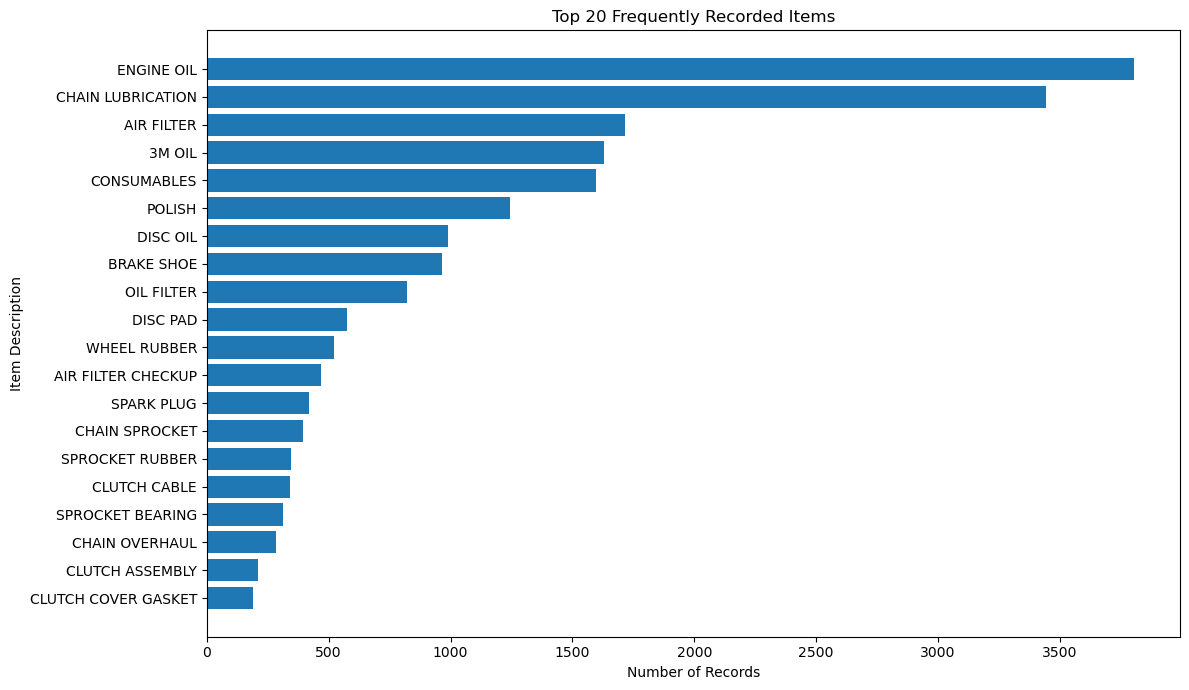

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    top_20_items['Item_Description'],
    top_20_items['Record_Count']
)

plt.xlabel('Number of Records')
plt.ylabel('Item Description')
plt.title('Top 20 Frequently Recorded Items')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [20]:
# Extract year and month from invoice date

df_analysis['Year_Month'] = (
    df_analysis['invoice_date'].dt.to_period('M')
)

# Calculate monthly recorded demand

monthly_demand = (
    df_analysis.groupby('Year_Month')
    .size()
    .reset_index(name='Record_Count')
)

monthly_demand['Year_Month'] = (
    monthly_demand['Year_Month'].astype(str)
)

display(monthly_demand.head(10))

print("Total months:", len(monthly_demand))

,Year_Month,Record_Count
0,2017-05,10
1,2017-06,1238
2,2017-07,1080
3,2017-08,881
4,2017-09,1152
5,2017-10,949
6,2017-11,1240
7,2017-12,1214
8,2018-01,893
9,2018-02,1197


Total months: 21


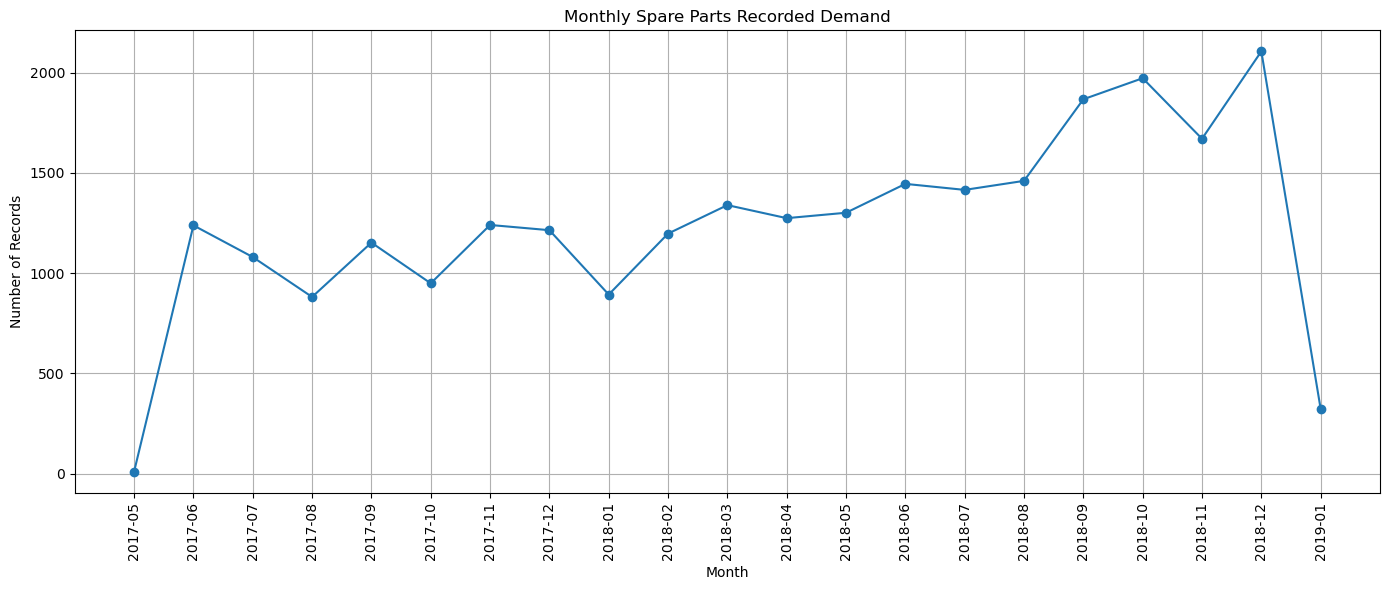

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_demand['Year_Month'],
    monthly_demand['Record_Count'],
    marker='o'
)

plt.xlabel('Month')
plt.ylabel('Number of Records')
plt.title('Monthly Spare Parts Recorded Demand')

plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [22]:
print("Average monthly records:",
      round(monthly_demand['Record_Count'].mean(), 2))

print("Maximum monthly records:",
      monthly_demand['Record_Count'].max())

print("Minimum monthly records:",
      monthly_demand['Record_Count'].min())

print("Highest demand month:",
      monthly_demand.loc[
          monthly_demand['Record_Count'].idxmax(),
          'Year_Month'
      ])

Average monthly records: 1239.29
Maximum monthly records: 2106
Minimum monthly records: 10
Highest demand month: 2018-12


In [23]:
# Extract invoice month
df_analysis['invoice_month'] = (
    df_analysis['invoice_date'].dt.to_period('M')
)

# Calculate monthly records for each item
monthly_item_demand = (
    df_analysis.groupby(
        ['invoice_month', 'item_description']
    )
    .size()
    .reset_index(name='record_count')
)

print("Item-wise monthly demand prepared successfully!")

Item-wise monthly demand prepared successfully!


In [24]:
# Identify the 10 most frequently recorded items
top_10_items = (
    df_analysis['item_description']
    .value_counts()
    .head(10)
    .index
)

# Filter monthly demand for these 10 items
top_10_monthly = monthly_item_demand[
    monthly_item_demand['item_description'].isin(top_10_items)
]

display(top_10_monthly.head(15))

,invoice_month,item_description,record_count
0,2017-05,3M OIL,2
1,2017-05,CHAIN LUBRICATION,2
2,2017-05,ENGINE OIL,5
3,2017-05,OIL FILTER,1
4,2017-06,3M OIL,88
7,2017-06,AIR FILTER,5
14,2017-06,BRAKE SHOE,44
20,2017-06,CHAIN LUBRICATION,167
34,2017-06,CONSUMABLES,79
40,2017-06,DISC OIL,71


In [25]:
# Convert data into a monthly demand matrix
demand_matrix = top_10_monthly.pivot(
    index='invoice_month',
    columns='item_description',
    values='record_count'
).fillna(0)

# Include every month in the dataset
all_months = pd.period_range(
    start=df_analysis['invoice_month'].min(),
    end=df_analysis['invoice_month'].max(),
    freq='M'
)

demand_matrix = demand_matrix.reindex(
    all_months,
    fill_value=0
)

display(demand_matrix.head(10))

item_description,3M OIL,AIR FILTER,BRAKE SHOE,CHAIN LUBRICATION,CONSUMABLES,DISC OIL,DISC PAD,ENGINE OIL,OIL FILTER,POLISH
2017-05,2.0,0.0,0.0,2.0,0.0,0.0,0.0,5.0,1.0,0.0
2017-06,88.0,5.0,44.0,167.0,79.0,71.0,26.0,179.0,34.0,66.0
2017-07,75.0,34.0,35.0,158.0,75.0,51.0,28.0,172.0,21.0,67.0
2017-08,64.0,52.0,29.0,138.0,59.0,19.0,19.0,146.0,29.0,52.0
2017-09,81.0,77.0,36.0,178.0,80.0,32.0,23.0,187.0,25.0,50.0
2017-10,68.0,70.0,41.0,138.0,64.0,30.0,15.0,158.0,27.0,46.0
2017-11,82.0,89.0,51.0,178.0,81.0,36.0,33.0,191.0,26.0,66.0
2017-12,85.0,112.0,47.0,202.0,79.0,20.0,31.0,213.0,33.0,52.0
2018-01,63.0,77.0,38.0,138.0,61.0,16.0,24.0,154.0,22.0,40.0
2018-02,82.0,86.0,50.0,183.0,81.0,27.0,34.0,199.0,33.0,49.0


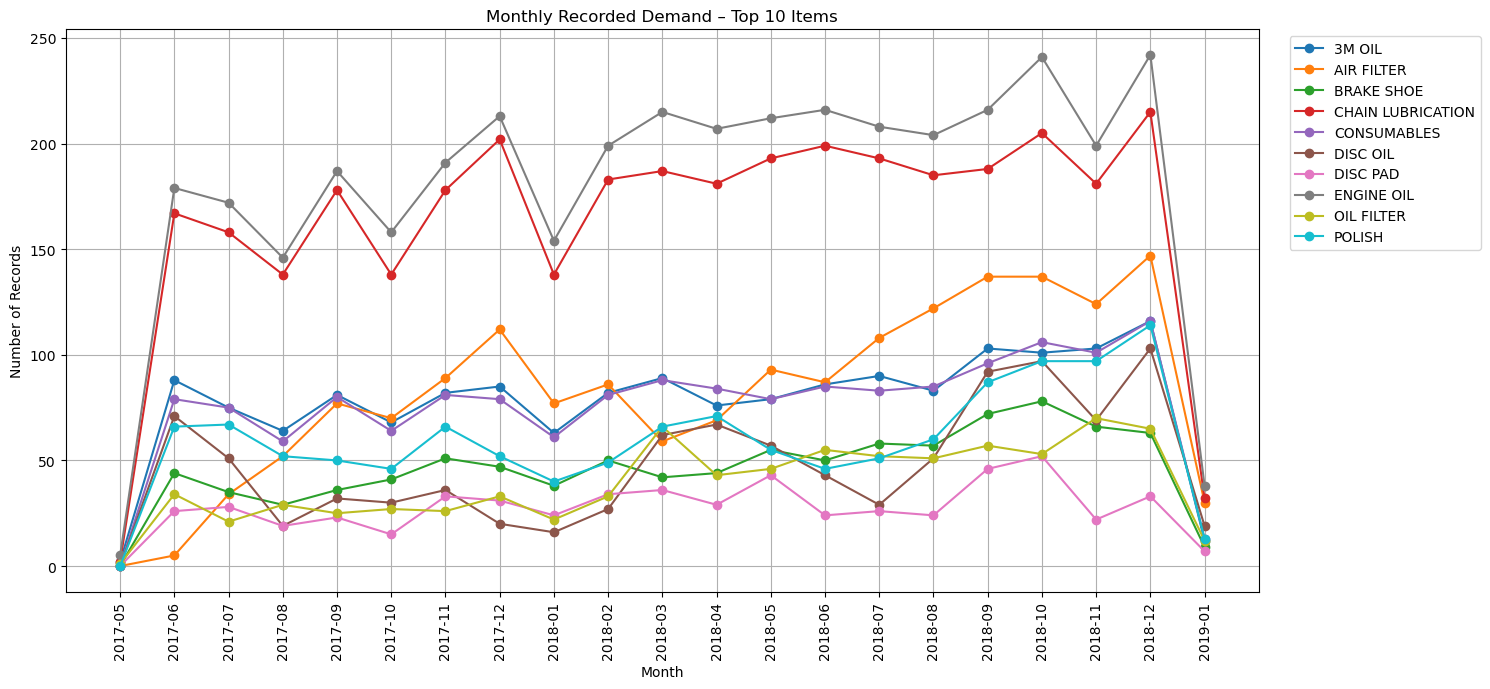

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

for item in demand_matrix.columns:
    plt.plot(
        demand_matrix.index.astype(str),
        demand_matrix[item],
        marker='o',
        label=item
    )

plt.title('Monthly Recorded Demand – Top 10 Items')
plt.xlabel('Month')
plt.ylabel('Number of Records')
plt.xticks(rotation=90)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# Forecasting dataset information

print("Dataset shape:", demand_matrix.shape)

print("First month:", demand_matrix.index.min())

print("Last month:", demand_matrix.index.max())

print("Number of months:", len(demand_matrix))

print("Number of items:", len(demand_matrix.columns))

print("\nMissing values:")
print(demand_matrix.isnull().sum().sum())

print("\nZero-demand records:")
print((demand_matrix == 0).sum().sum())

Dataset shape: (21, 10)
First month: 2017-05
Last month: 2019-01
Number of months: 21
Number of items: 10

Missing values:
0

Zero-demand records:
6


In [28]:
# Calculate the split point

split_point = int(len(demand_matrix) * 0.8)

# Training dataset
train_data = demand_matrix.iloc[:split_point].copy()

# Testing dataset
test_data = demand_matrix.iloc[split_point:].copy()

print("Training dataset shape:", train_data.shape)
print("Testing dataset shape:", test_data.shape)

print("\nTraining period:")
print(train_data.index.min(), "to", train_data.index.max())

print("\nTesting period:")
print(test_data.index.min(), "to", test_data.index.max())

Training dataset shape: (16, 10)
Testing dataset shape: (5, 10)

Training period:
2017-05 to 2018-08

Testing period:
2018-09 to 2019-01


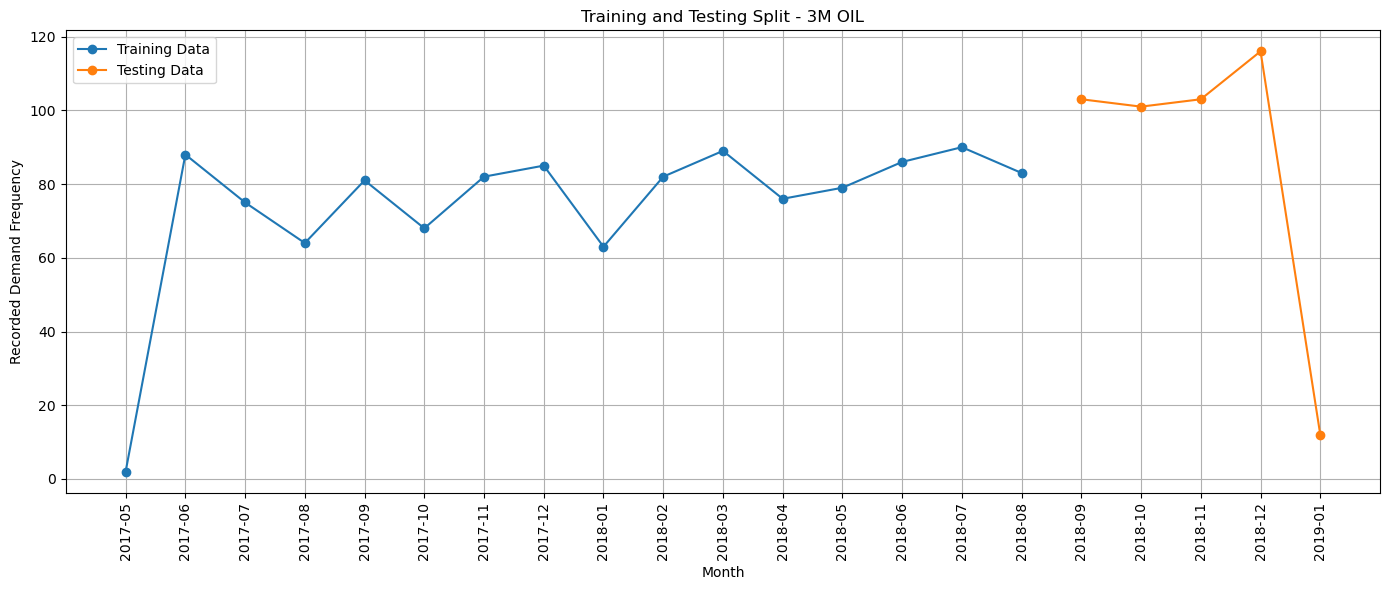

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    train_data.index.astype(str),
    train_data.iloc[:, 0],
    marker='o',
    label='Training Data'
)

plt.plot(
    test_data.index.astype(str),
    test_data.iloc[:, 0],
    marker='o',
    label='Testing Data'
)

plt.title(
    f'Training and Testing Split - {demand_matrix.columns[0]}'
)

plt.xlabel('Month')
plt.ylabel('Recorded Demand Frequency')
plt.xticks(rotation=90)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
# Moving Average Forecasting Model

window_size = 3

moving_average_forecast = {}

for item in demand_matrix.columns:

    historical_data = train_data[item]

    forecast_value = historical_data.tail(
        window_size
    ).mean()

    moving_average_forecast[item] = [
        forecast_value
    ] * len(test_data)

print("Moving Average model created successfully!")

Moving Average model created successfully!


In [31]:
# Convert predictions into a DataFrame

ma_predictions = pd.DataFrame(
    moving_average_forecast,
    index=test_data.index
)

display(ma_predictions.head())

,3M OIL,AIR FILTER,BRAKE SHOE,CHAIN LUBRICATION,CONSUMABLES,DISC OIL,DISC PAD,ENGINE OIL,OIL FILTER,POLISH
2018-09,86.333333,105.666667,55.0,192.333333,84.333333,41.0,24.666667,209.333333,52.666667,52.333333
2018-10,86.333333,105.666667,55.0,192.333333,84.333333,41.0,24.666667,209.333333,52.666667,52.333333
2018-11,86.333333,105.666667,55.0,192.333333,84.333333,41.0,24.666667,209.333333,52.666667,52.333333
2018-12,86.333333,105.666667,55.0,192.333333,84.333333,41.0,24.666667,209.333333,52.666667,52.333333
2019-01,86.333333,105.666667,55.0,192.333333,84.333333,41.0,24.666667,209.333333,52.666667,52.333333


In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

ma_results = []

for item in demand_matrix.columns:

    actual = test_data[item]
    predicted = ma_predictions[item]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    non_zero = actual != 0

    if non_zero.sum() > 0:
        mape = (
            np.abs(
                (actual[non_zero] - predicted[non_zero])
                / actual[non_zero]
            ).mean()
        ) * 100
    else:
        mape = np.nan

    ma_results.append({
        'Item': item,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE_NonZero_Percent': round(mape, 2)
        if not np.isnan(mape) else np.nan
    })

ma_evaluation = pd.DataFrame(ma_results)

display(ma_evaluation)

,Item,MAE,RMSE,MAPE_NonZero_Percent
0,3M OIL,30.40,37.88,138.38
1,AIR FILTER,39.60,44.12,68.17
2,BRAKE SHOE,21.00,24.98,118.71
3,CHAIN LUBRICATION,42.27,72.84,105.27
4,CONSUMABLES,30.60,37.35,125.02
5,DISC OIL,43.80,46.58,65.95
6,DISC PAD,15.47,17.84,77.74
7,ENGINE OIL,50.53,79.47,97.16
8,OIL FILTER,15.00,20.62,78.17
9,POLISH,45.00,45.92,97.72


In [33]:
ma_evaluation.to_csv(
    'moving_average_evaluation.csv',
    index=False
)

print("Moving Average evaluation saved successfully!")

Moving Average evaluation saved successfully!


In [34]:
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

print("Simple Exponential Smoothing imported successfully!")

Simple Exponential Smoothing imported successfully!


In [35]:
# Exponential Smoothing Forecasting

es_predictions = pd.DataFrame(index=test_data.index)

for item in demand_matrix.columns:

    historical_data = train_data[item].astype(float)

    try:
        model = SimpleExpSmoothing(
            historical_data,
            initialization_method='estimated'
        )

        fitted_model = model.fit(optimized=True)

        forecast = fitted_model.forecast(
            len(test_data)
        )

        es_predictions[item] = forecast.values

    except Exception as e:
        print(f"Error for {item}: {e}")
        es_predictions[item] = historical_data.mean()

print("Exponential Smoothing predictions generated!")

Exponential Smoothing predictions generated!


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

es_results = []

for item in demand_matrix.columns:

    actual = test_data[item]
    predicted = es_predictions[item]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    non_zero = actual != 0

    if non_zero.sum() > 0:
        mape = (
            np.abs(
                (actual[non_zero] - predicted[non_zero])
                / actual[non_zero]
            ).mean()
        ) * 100
    else:
        mape = np.nan

    es_results.append({
        'Item': item,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE_NonZero_Percent': round(mape, 2)
        if not np.isnan(mape) else np.nan
    })

es_evaluation = pd.DataFrame(es_results)

display(es_evaluation)

,Item,MAE,RMSE,MAPE_NonZero_Percent
0,3M OIL,33.78,38.40,133.26
1,AIR FILTER,29.92,43.65,69.42
2,BRAKE SHOE,21.16,25.00,118.43
3,CHAIN LUBRICATION,41.45,71.36,102.60
4,CONSUMABLES,31.83,37.52,123.44
5,DISC OIL,45.49,48.73,65.54
6,DISC PAD,14.83,16.78,85.22
7,ENGINE OIL,51.01,78.84,96.28
8,OIL FILTER,16.11,20.59,77.53
9,POLISH,45.01,45.93,97.71


In [37]:
es_evaluation.to_csv(
    'exponential_smoothing_evaluation.csv',
    index=False
)

print("Exponential Smoothing results saved!")

Exponential Smoothing results saved!


In [38]:
model_comparison = pd.DataFrame({
    'Item': ma_evaluation['Item'],
    'Moving_Average_MAE': ma_evaluation['MAE'],
    'Exponential_Smoothing_MAE': es_evaluation['MAE']
})

model_comparison['Best_Model'] = np.where(
    model_comparison['Moving_Average_MAE']
    < model_comparison['Exponential_Smoothing_MAE'],
    'Moving Average',
    np.where(
        model_comparison['Moving_Average_MAE']
        > model_comparison['Exponential_Smoothing_MAE'],
        'Exponential Smoothing',
        'Both Equal'
    )
)

display(model_comparison)

,Item,Moving_Average_MAE,Exponential_Smoothing_MAE,Best_Model
0,3M OIL,30.40,33.78,Moving Average
1,AIR FILTER,39.60,29.92,Exponential Smoothing
2,BRAKE SHOE,21.00,21.16,Moving Average
3,CHAIN LUBRICATION,42.27,41.45,Exponential Smoothing
4,CONSUMABLES,30.60,31.83,Moving Average
5,DISC OIL,43.80,45.49,Moving Average
6,DISC PAD,15.47,14.83,Exponential Smoothing
7,ENGINE OIL,50.53,51.01,Moving Average
8,OIL FILTER,15.00,16.11,Moving Average
9,POLISH,45.00,45.01,Moving Average


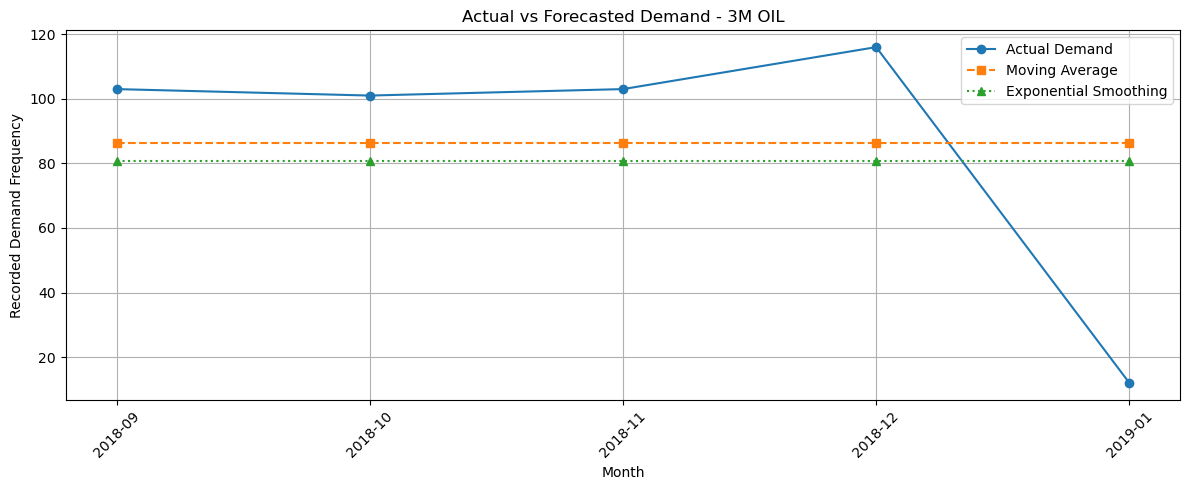

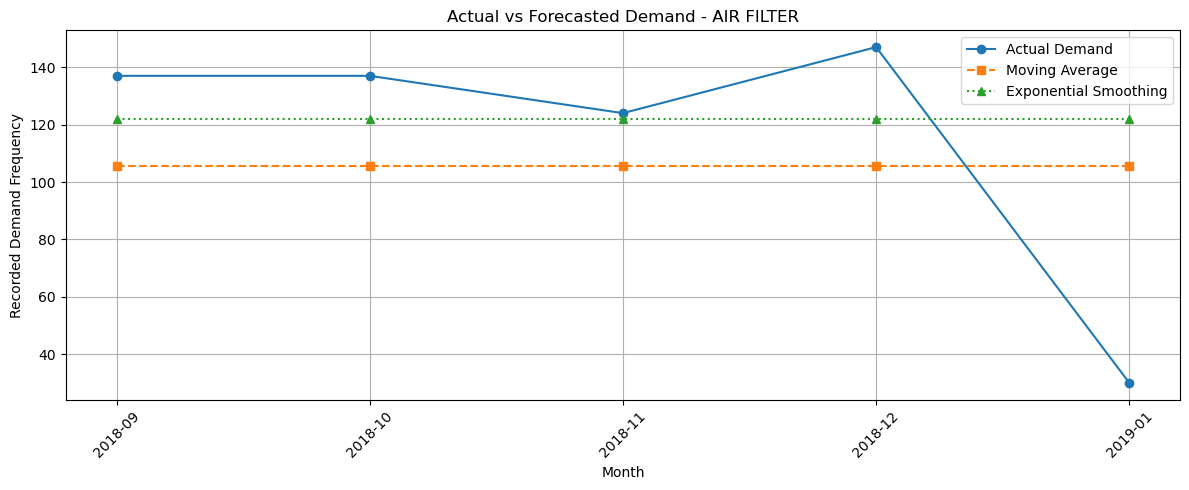

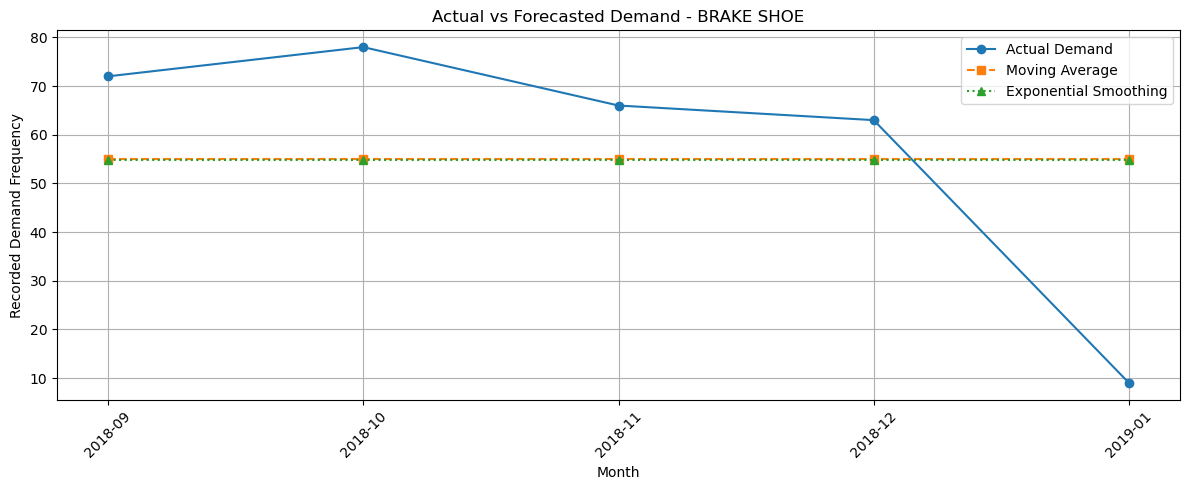

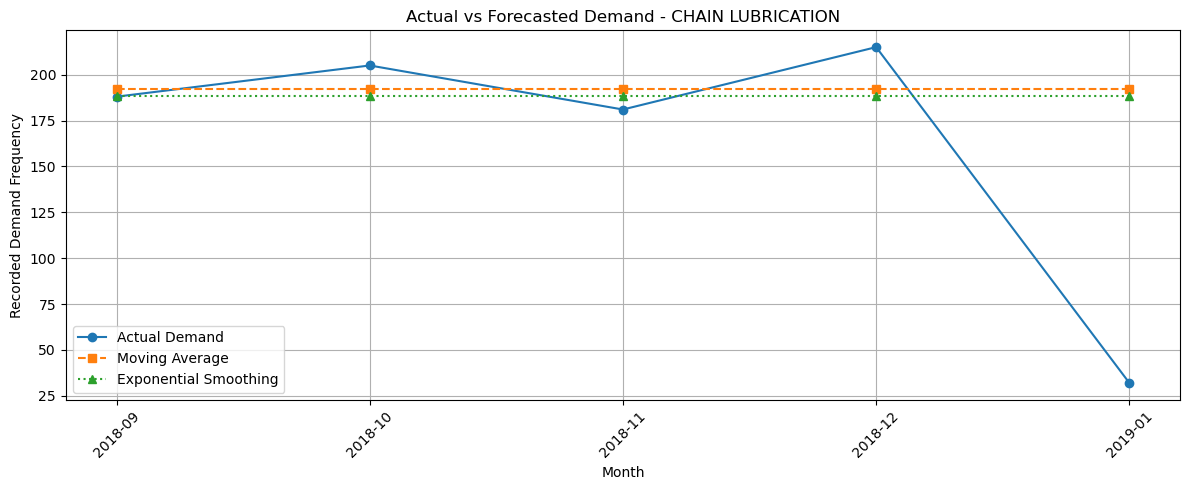

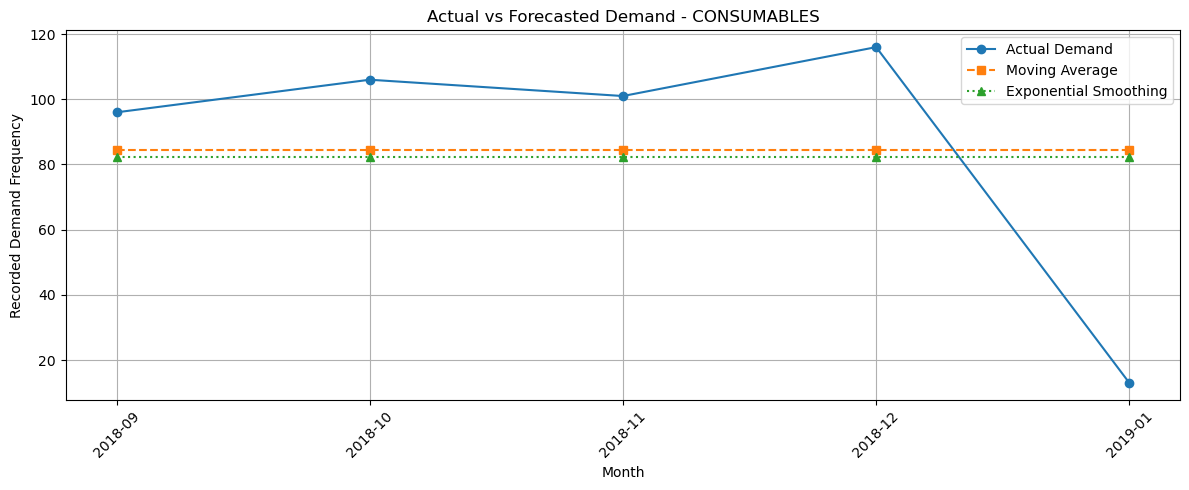

In [39]:
import matplotlib.pyplot as plt

items_to_plot = demand_matrix.columns[:5]

for item in items_to_plot:

    plt.figure(figsize=(12, 5))

    plt.plot(
        test_data.index.astype(str),
        test_data[item],
        marker='o',
        label='Actual Demand'
    )

    plt.plot(
        test_data.index.astype(str),
        ma_predictions[item],
        marker='s',
        linestyle='--',
        label='Moving Average'
    )

    plt.plot(
        test_data.index.astype(str),
        es_predictions[item],
        marker='^',
        linestyle=':',
        label='Exponential Smoothing'
    )

    plt.title(f'Actual vs Forecasted Demand - {item}')
    plt.xlabel('Month')
    plt.ylabel('Recorded Demand Frequency')
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [40]:
overall_comparison = pd.DataFrame({
    'Model': [
        'Moving Average',
        'Exponential Smoothing'
    ],
    'Average_MAE': [
        ma_evaluation['MAE'].mean(),
        es_evaluation['MAE'].mean()
    ],
    'Average_RMSE': [
        ma_evaluation['RMSE'].mean(),
        es_evaluation['RMSE'].mean()
    ]
})

display(overall_comparison)

,Model,Average_MAE,Average_RMSE
0,Moving Average,33.367,42.76
1,Exponential Smoothing,33.059,42.68


In [41]:
model_comparison.to_csv(
    'model_comparison_by_item.csv',
    index=False
)

overall_comparison.to_csv(
    'overall_model_comparison.csv',
    index=False
)

print("Model comparison files saved successfully!")

Model comparison files saved successfully!


In [42]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

print("Holt's Linear Trend library imported successfully!")

Holt's Linear Trend library imported successfully!


In [43]:
holt_predictions = pd.DataFrame(index=test_data.index)

for item in demand_matrix.columns:

    historical_data = train_data[item].astype(float)

    try:
        model = ExponentialSmoothing(
            historical_data,
            trend='add',
            seasonal=None,
            initialization_method='estimated'
        )

        fitted_model = model.fit(
            optimized=True
        )

        forecast = fitted_model.forecast(
            len(test_data)
        )

        # Demand cannot be negative
        holt_predictions[item] = forecast.clip(lower=0).values

    except Exception as e:
        print(f"Error for {item}: {e}")
        holt_predictions[item] = historical_data.mean()

print("Holt's Linear Trend predictions generated!")

Holt's Linear Trend predictions generated!


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

holt_results = []

for item in demand_matrix.columns:

    actual = test_data[item]
    predicted = holt_predictions[item]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    non_zero = actual != 0

    if non_zero.sum() > 0:
        mape = (
            np.abs(
                (actual[non_zero] - predicted[non_zero])
                / actual[non_zero]
            ).mean()
        ) * 100
    else:
        mape = np.nan

    holt_results.append({
        'Item': item,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE_NonZero_Percent': round(mape, 2)
        if not np.isnan(mape) else np.nan
    })

holt_evaluation = pd.DataFrame(holt_results)

display(holt_evaluation)

,Item,MAE,RMSE,MAPE_NonZero_Percent
0,3M OIL,24.97,41.56,157.87
1,AIR FILTER,33.24,59.51,92.74
2,BRAKE SHOE,18.37,28.43,143.25
3,CHAIN LUBRICATION,65.11,97.91,143.21
4,CONSUMABLES,23.46,41.71,145.86
5,DISC OIL,38.64,40.37,70.61
6,DISC PAD,15.66,18.00,116.70
7,ENGINE OIL,66.51,106.57,130.70
8,OIL FILTER,14.82,25.96,100.88
9,POLISH,39.47,40.70,108.92


In [45]:
all_model_comparison = pd.DataFrame({
    'Item': ma_evaluation['Item'],
    'Moving_Average_MAE': ma_evaluation['MAE'],
    'Exponential_Smoothing_MAE': es_evaluation['MAE'],
    'Holt_Trend_MAE': holt_evaluation['MAE']
})

mae_columns = [
    'Moving_Average_MAE',
    'Exponential_Smoothing_MAE',
    'Holt_Trend_MAE'
]

model_names = {
    'Moving_Average_MAE': 'Moving Average',
    'Exponential_Smoothing_MAE': 'Exponential Smoothing',
    'Holt_Trend_MAE': "Holt's Linear Trend"
}

all_model_comparison['Best_Model'] = (
    all_model_comparison[mae_columns]
    .idxmin(axis=1)
    .map(model_names)
)

display(all_model_comparison)

,Item,Moving_Average_MAE,Exponential_Smoothing_MAE,Holt_Trend_MAE,Best_Model
0,3M OIL,30.40,33.78,24.97,Holt's Linear Trend
1,AIR FILTER,39.60,29.92,33.24,Exponential Smoothing
2,BRAKE SHOE,21.00,21.16,18.37,Holt's Linear Trend
3,CHAIN LUBRICATION,42.27,41.45,65.11,Exponential Smoothing
4,CONSUMABLES,30.60,31.83,23.46,Holt's Linear Trend
5,DISC OIL,43.80,45.49,38.64,Holt's Linear Trend
6,DISC PAD,15.47,14.83,15.66,Exponential Smoothing
7,ENGINE OIL,50.53,51.01,66.51,Moving Average
8,OIL FILTER,15.00,16.11,14.82,Holt's Linear Trend
9,POLISH,45.00,45.01,39.47,Holt's Linear Trend


In [46]:
all_model_comparison.to_csv(
    'all_three_models_comparison.csv',
    index=False
)

holt_evaluation.to_csv(
    'holt_trend_evaluation.csv',
    index=False
)

print("All three model comparison results saved successfully!")

All three model comparison results saved successfully!


In [47]:
# Generate forecasts for the next 3 months

future_months = pd.period_range(
    start=demand_matrix.index[-1] + 1,
    periods=3,
    freq='M'
)

future_forecasts = pd.DataFrame(
    index=future_months
)

# Store selected models
best_models = all_model_comparison.set_index('Item')['Best_Model']

for item in demand_matrix.columns:

    historical_data = demand_matrix[item].astype(float)

    selected_model = best_models[item]

    if selected_model == 'Moving Average':

        forecast_value = historical_data.tail(3).mean()

        predictions = [forecast_value] * 3

    elif selected_model == 'Exponential Smoothing':

        model = SimpleExpSmoothing(
            historical_data,
            initialization_method='estimated'
        )

        fitted_model = model.fit(optimized=True)

        predictions = fitted_model.forecast(3).values

    elif selected_model == "Holt's Linear Trend":

        model = ExponentialSmoothing(
            historical_data,
            trend='add',
            seasonal=None,
            initialization_method='estimated'
        )

        fitted_model = model.fit(optimized=True)

        predictions = fitted_model.forecast(3).values

    # Prevent negative demand predictions
    predictions = np.maximum(predictions, 0)

    future_forecasts[item] = predictions

print("Three-month forecasting completed!")

display(future_forecasts.round(2))

Three-month forecasting completed!


,3M OIL,AIR FILTER,BRAKE SHOE,CHAIN LUBRICATION,CONSUMABLES,DISC OIL,DISC PAD,ENGINE OIL,OIL FILTER,POLISH
2019-02,93.28,53.85,63.28,163.86,94.04,72.85,27.38,159.67,60.37,79.04
2019-03,94.71,53.85,64.86,163.86,95.68,75.18,27.38,159.67,62.30,80.84
2019-04,96.15,53.85,66.43,163.86,97.33,77.51,27.38,159.67,64.23,82.64


In [48]:
# Convert forecast matrix into a readable table

forecast_summary = (
    future_forecasts
    .reset_index()
    .rename(columns={'index': 'Forecast_Month'})
    .melt(
        id_vars='Forecast_Month',
        var_name='Item_Description',
        value_name='Predicted_Record_Count'
    )
)

forecast_summary['Forecast_Month'] = (
    forecast_summary['Forecast_Month'].astype(str)
)

forecast_summary['Predicted_Record_Count'] = (
    forecast_summary['Predicted_Record_Count'].round(0).astype(int)
)

display(forecast_summary)

,Forecast_Month,Item_Description,Predicted_Record_Count
0,2019-02,3M OIL,93
1,2019-03,3M OIL,95
2,2019-04,3M OIL,96
3,2019-02,AIR FILTER,54
4,2019-03,AIR FILTER,54
5,2019-04,AIR FILTER,54
6,2019-02,BRAKE SHOE,63
7,2019-03,BRAKE SHOE,65
8,2019-04,BRAKE SHOE,66
9,2019-02,CHAIN LUBRICATION,164


In [49]:
forecast_summary.to_csv(
    'future_spare_parts_forecast.csv',
    index=False
)

print("Future forecasts saved successfully!")

Future forecasts saved successfully!


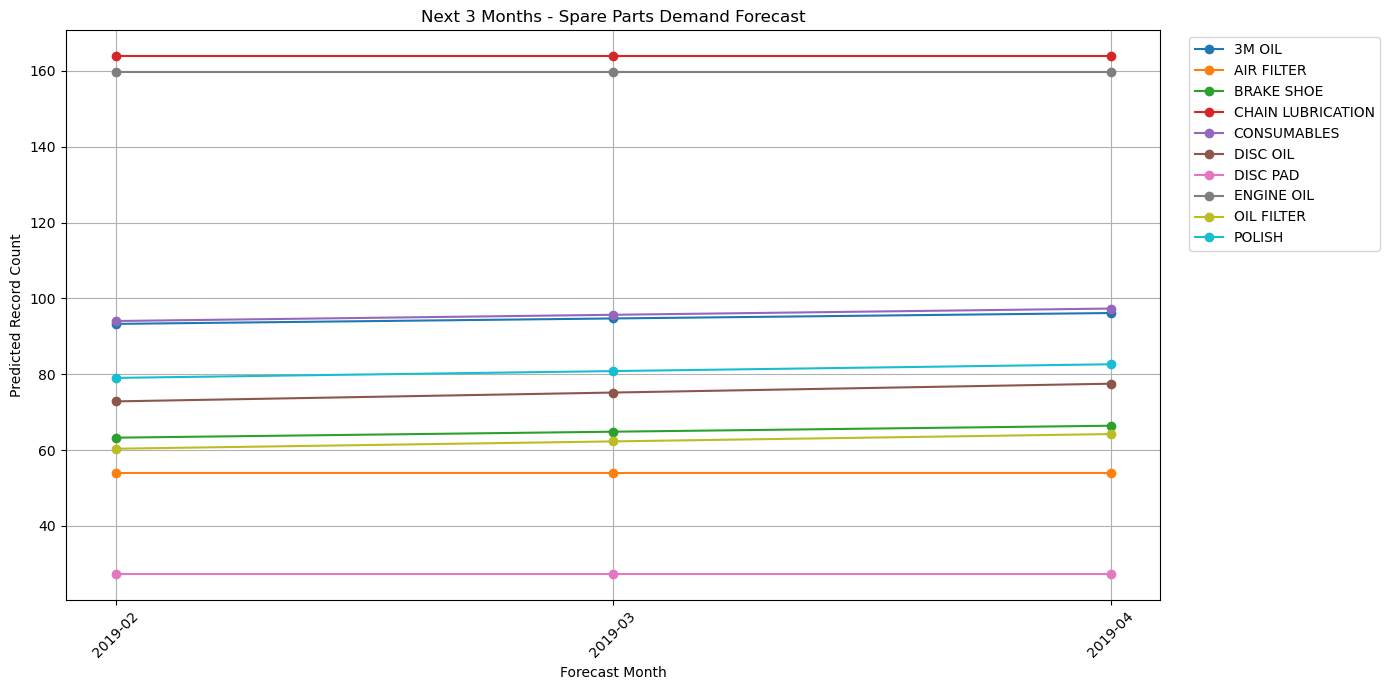

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))

for item in future_forecasts.columns:

    plt.plot(
        future_forecasts.index.astype(str),
        future_forecasts[item],
        marker='o',
        label=item
    )

plt.title('Next 3 Months - Spare Parts Demand Forecast')
plt.xlabel('Forecast Month')
plt.ylabel('Predicted Record Count')

plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True)
plt.tight_layout()
plt.show()

In [51]:
# Calculate historical demand statistics for each item

inventory_analysis = pd.DataFrame(index=demand_matrix.columns)

inventory_analysis['Average_Monthly_Demand'] = (
    demand_matrix.mean()
)

inventory_analysis['Demand_Std_Dev'] = (
    demand_matrix.std()
)

inventory_analysis['Maximum_Monthly_Demand'] = (
    demand_matrix.max()
)

inventory_analysis['Minimum_Monthly_Demand'] = (
    demand_matrix.min()
)

inventory_analysis['Months_With_Zero_Demand'] = (
    (demand_matrix == 0).sum()
)

inventory_analysis['Total_Recorded_Demand'] = (
    demand_matrix.sum()
)

inventory_analysis = inventory_analysis.round(2)

display(inventory_analysis)

,Average_Monthly_Demand,Demand_Std_Dev,Maximum_Monthly_Demand,Minimum_Monthly_Demand,Months_With_Zero_Demand,Total_Recorded_Demand
item_description,,,,,,
3M OIL,77.52,26.86,116.0,2.0,0,1628.0
AIR FILTER,81.67,41.76,147.0,0.0,1,1715.0
BRAKE SHOE,45.95,18.58,78.0,0.0,1,965.0
CHAIN LUBRICATION,163.86,53.50,215.0,2.0,0,3441.0
CONSUMABLES,75.95,26.87,116.0,0.0,1,1595.0
DISC OIL,47.19,28.57,103.0,0.0,1,991.0
DISC PAD,27.38,11.98,52.0,0.0,1,575.0
ENGINE OIL,181.05,59.00,242.0,5.0,0,3802.0
OIL FILTER,39.10,18.72,70.0,1.0,0,821.0


In [52]:
# Calculate zero-demand percentage

inventory_analysis['Zero_Demand_Percentage'] = (
    inventory_analysis['Months_With_Zero_Demand']
    / len(demand_matrix)
) * 100


def demand_category(zero_percentage):

    if zero_percentage <= 20:
        return 'Regular Demand'

    elif zero_percentage <= 50:
        return 'Occasional Demand'

    else:
        return 'Intermittent Demand'


inventory_analysis['Demand_Category'] = (
    inventory_analysis['Zero_Demand_Percentage']
    .apply(demand_category)
)

display(inventory_analysis)

,Average_Monthly_Demand,Demand_Std_Dev,Maximum_Monthly_Demand,Minimum_Monthly_Demand,Months_With_Zero_Demand,Total_Recorded_Demand,Zero_Demand_Percentage,Demand_Category
item_description,,,,,,,,
3M OIL,77.52,26.86,116.0,2.0,0,1628.0,0.000000,Regular Demand
AIR FILTER,81.67,41.76,147.0,0.0,1,1715.0,4.761905,Regular Demand
BRAKE SHOE,45.95,18.58,78.0,0.0,1,965.0,4.761905,Regular Demand
CHAIN LUBRICATION,163.86,53.50,215.0,2.0,0,3441.0,0.000000,Regular Demand
CONSUMABLES,75.95,26.87,116.0,0.0,1,1595.0,4.761905,Regular Demand
DISC OIL,47.19,28.57,103.0,0.0,1,991.0,4.761905,Regular Demand
DISC PAD,27.38,11.98,52.0,0.0,1,575.0,4.761905,Regular Demand
ENGINE OIL,181.05,59.00,242.0,5.0,0,3802.0,0.000000,Regular Demand
OIL FILTER,39.10,18.72,70.0,1.0,0,821.0,0.000000,Regular Demand


In [53]:
# Rank items based on total recorded demand

inventory_analysis['Demand_Rank'] = (
    inventory_analysis['Total_Recorded_Demand']
    .rank(method='dense', ascending=False)
    .astype(int)
)

inventory_analysis = inventory_analysis.sort_values(
    by='Total_Recorded_Demand',
    ascending=False
)

display(inventory_analysis)

,Average_Monthly_Demand,Demand_Std_Dev,Maximum_Monthly_Demand,Minimum_Monthly_Demand,Months_With_Zero_Demand,Total_Recorded_Demand,Zero_Demand_Percentage,Demand_Category,Demand_Rank
item_description,,,,,,,,,
ENGINE OIL,181.05,59.00,242.0,5.0,0,3802.0,0.000000,Regular Demand,1
CHAIN LUBRICATION,163.86,53.50,215.0,2.0,0,3441.0,0.000000,Regular Demand,2
AIR FILTER,81.67,41.76,147.0,0.0,1,1715.0,4.761905,Regular Demand,3
3M OIL,77.52,26.86,116.0,2.0,0,1628.0,0.000000,Regular Demand,4
CONSUMABLES,75.95,26.87,116.0,0.0,1,1595.0,4.761905,Regular Demand,5
POLISH,59.29,26.18,114.0,0.0,1,1245.0,4.761905,Regular Demand,6
DISC OIL,47.19,28.57,103.0,0.0,1,991.0,4.761905,Regular Demand,7
BRAKE SHOE,45.95,18.58,78.0,0.0,1,965.0,4.761905,Regular Demand,8
OIL FILTER,39.10,18.72,70.0,1.0,0,821.0,0.000000,Regular Demand,9


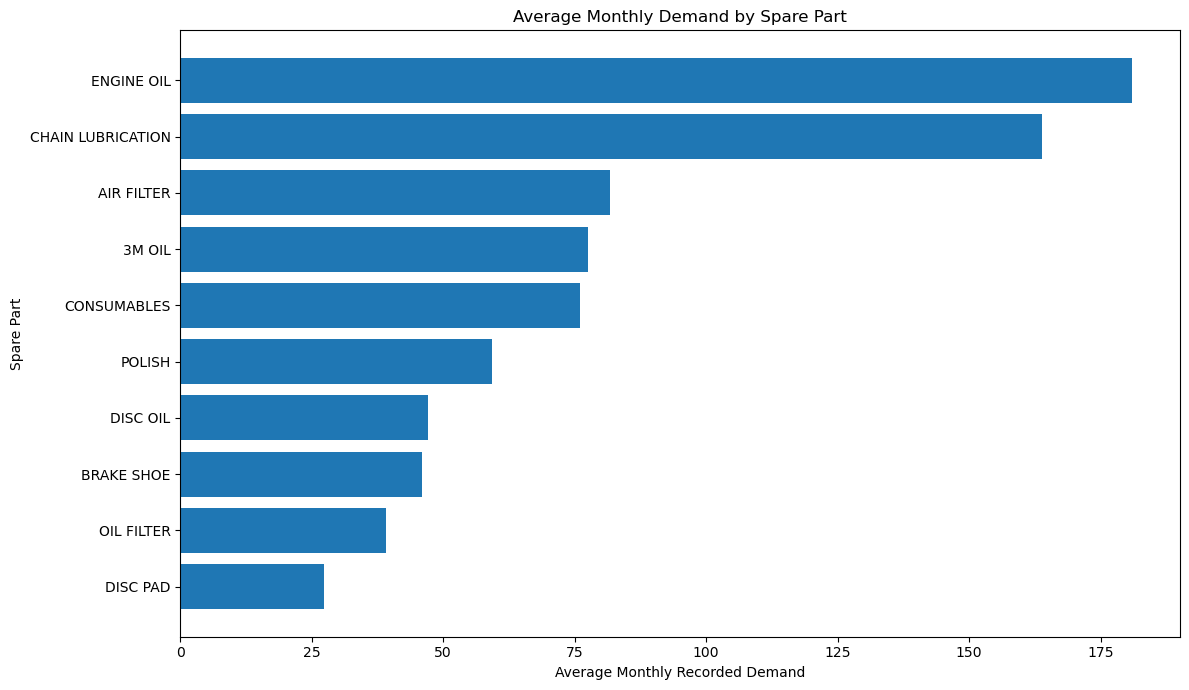

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    inventory_analysis.index,
    inventory_analysis['Average_Monthly_Demand']
)

plt.xlabel('Average Monthly Recorded Demand')
plt.ylabel('Spare Part')
plt.title('Average Monthly Demand by Spare Part')

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [55]:
inventory_analysis.to_csv(
    'spare_parts_inventory_analysis.csv'
)

print("Inventory analysis saved successfully!")

Inventory analysis saved successfully!


In [56]:
# Calculate each item's contribution to total recorded demand

priority_analysis = inventory_analysis.copy()

total_demand = priority_analysis[
    'Total_Recorded_Demand'
].sum()

priority_analysis['Demand_Contribution_Percent'] = (
    priority_analysis['Total_Recorded_Demand']
    / total_demand
) * 100

priority_analysis = priority_analysis.sort_values(
    by='Total_Recorded_Demand',
    ascending=False
)

priority_analysis['Cumulative_Contribution_Percent'] = (
    priority_analysis['Demand_Contribution_Percent'].cumsum()
)

priority_analysis = priority_analysis.round(2)

display(priority_analysis)

,Average_Monthly_Demand,Demand_Std_Dev,Maximum_Monthly_Demand,Minimum_Monthly_Demand,Months_With_Zero_Demand,Total_Recorded_Demand,Zero_Demand_Percentage,Demand_Category,Demand_Rank,Demand_Contribution_Percent,Cumulative_Contribution_Percent
item_description,,,,,,,,,,,
ENGINE OIL,181.05,59.00,242.0,5.0,0,3802.0,0.00,Regular Demand,1,22.66,22.66
CHAIN LUBRICATION,163.86,53.50,215.0,2.0,0,3441.0,0.00,Regular Demand,2,20.51,43.17
AIR FILTER,81.67,41.76,147.0,0.0,1,1715.0,4.76,Regular Demand,3,10.22,53.39
3M OIL,77.52,26.86,116.0,2.0,0,1628.0,0.00,Regular Demand,4,9.70,63.09
CONSUMABLES,75.95,26.87,116.0,0.0,1,1595.0,4.76,Regular Demand,5,9.51,72.60
POLISH,59.29,26.18,114.0,0.0,1,1245.0,4.76,Regular Demand,6,7.42,80.02
DISC OIL,47.19,28.57,103.0,0.0,1,991.0,4.76,Regular Demand,7,5.91,85.93
BRAKE SHOE,45.95,18.58,78.0,0.0,1,965.0,4.76,Regular Demand,8,5.75,91.68
OIL FILTER,39.10,18.72,70.0,1.0,0,821.0,0.00,Regular Demand,9,4.89,96.57


In [57]:
def assign_priority(cumulative):

    if cumulative <= 70:
        return 'A'

    elif cumulative <= 90:
        return 'B'

    else:
        return 'C'


priority_analysis['Priority_Category'] = (
    priority_analysis['Cumulative_Contribution_Percent']
    .apply(assign_priority)
)

display(
    priority_analysis[
        [
            'Total_Recorded_Demand',
            'Demand_Contribution_Percent',
            'Cumulative_Contribution_Percent',
            'Priority_Category'
        ]
    ]
)

,Total_Recorded_Demand,Demand_Contribution_Percent,Cumulative_Contribution_Percent,Priority_Category
item_description,,,,
ENGINE OIL,3802.0,22.66,22.66,A
CHAIN LUBRICATION,3441.0,20.51,43.17,A
AIR FILTER,1715.0,10.22,53.39,A
3M OIL,1628.0,9.70,63.09,A
CONSUMABLES,1595.0,9.51,72.60,B
POLISH,1245.0,7.42,80.02,B
DISC OIL,991.0,5.91,85.93,B
BRAKE SHOE,965.0,5.75,91.68,C
OIL FILTER,821.0,4.89,96.57,C


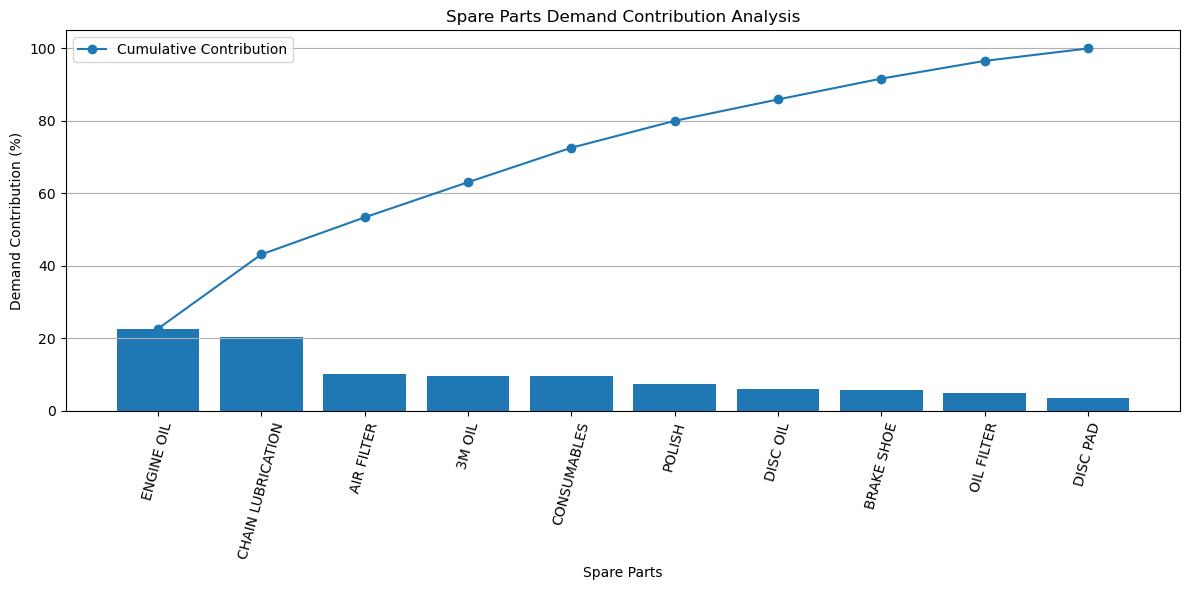

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    priority_analysis.index,
    priority_analysis['Demand_Contribution_Percent']
)

plt.plot(
    priority_analysis.index,
    priority_analysis['Cumulative_Contribution_Percent'],
    marker='o',
    label='Cumulative Contribution'
)

plt.xlabel('Spare Parts')
plt.ylabel('Demand Contribution (%)')
plt.title('Spare Parts Demand Contribution Analysis')

plt.xticks(rotation=75)
plt.legend()
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [59]:
priority_analysis.to_csv(
    'spare_parts_priority_analysis.csv'
)

print("Priority analysis saved successfully!")

Priority analysis saved successfully!


In [60]:
# Create a classification lookup
classification_map = dict(
    zip(
        service_candidates['Item_Description'],
        service_candidates['Category']
    )
)

# Review the top 10 forecasted items
top_items_validation = pd.DataFrame({
    'Item_Description': demand_matrix.columns
})

top_items_validation['Classification'] = (
    top_items_validation['Item_Description']
    .map(classification_map)
    .fillna('NOT_FLAGGED')
)

# Add total historical record counts
record_counts = df_analysis['item_description'].value_counts()

top_items_validation['Total_Records'] = (
    top_items_validation['Item_Description']
    .map(record_counts)
)

display(top_items_validation)

,Item_Description,Classification,Total_Records
0,3M OIL,NOT_FLAGGED,1628
1,AIR FILTER,NOT_FLAGGED,1715
2,BRAKE SHOE,NOT_FLAGGED,965
3,CHAIN LUBRICATION,NOT_FLAGGED,3441
4,CONSUMABLES,NOT_FLAGGED,1595
5,DISC OIL,NOT_FLAGGED,991
6,DISC PAD,NOT_FLAGGED,575
7,ENGINE OIL,NOT_FLAGGED,3802
8,OIL FILTER,NOT_FLAGGED,821
9,POLISH,NOT_FLAGGED,1245


In [61]:
top_items_validation.to_csv(
    'top_10_items_validation.csv',
    index=False
)

print("Top 10 item validation saved successfully!")

Top 10 item validation saved successfully!


In [62]:
project_limitations = [
    "Dataset contains historical records from May 2017 to January 2019.",
    "Dataset does not contain a confirmed spare-parts quantity column.",
    "Service-related descriptions require business validation.",
    "Some invoice descriptions may contain both services and spare parts.",
    "Forecasting was initially performed on the top 10 recorded items.",
    "Only a limited historical period is available for model evaluation.",
    "Current stock levels and supplier lead times are unavailable.",
    "Forecasts represent invoice-line frequencies, not confirmed physical quantities."
]

for number, limitation in enumerate(project_limitations, start=1):
    print(f"{number}. {limitation}")

1. Dataset contains historical records from May 2017 to January 2019.
2. Dataset does not contain a confirmed spare-parts quantity column.
3. Service-related descriptions require business validation.
4. Some invoice descriptions may contain both services and spare parts.
5. Forecasting was initially performed on the top 10 recorded items.
6. Only a limited historical period is available for model evaluation.
7. Current stock levels and supplier lead times are unavailable.
8. Forecasts represent invoice-line frequencies, not confirmed physical quantities.


In [63]:
# Final model performance comparison

final_model_results = pd.DataFrame({
    'Item': ma_evaluation['Item'],
    'Moving_Average_MAE': ma_evaluation['MAE'],
    'Moving_Average_RMSE': ma_evaluation['RMSE'],
    'Exponential_Smoothing_MAE': es_evaluation['MAE'],
    'Exponential_Smoothing_RMSE': es_evaluation['RMSE'],
    'Holt_Trend_MAE': holt_evaluation['MAE'],
    'Holt_Trend_RMSE': holt_evaluation['RMSE']
})

mae_columns = [
    'Moving_Average_MAE',
    'Exponential_Smoothing_MAE',
    'Holt_Trend_MAE'
]

final_model_results['Best_Model'] = (
    final_model_results[mae_columns]
    .idxmin(axis=1)
    .map({
        'Moving_Average_MAE': 'Moving Average',
        'Exponential_Smoothing_MAE': 'Exponential Smoothing',
        'Holt_Trend_MAE': "Holt's Linear Trend"
    })
)

display(final_model_results)

,Item,Moving_Average_MAE,Moving_Average_RMSE,Exponential_Smoothing_MAE,Exponential_Smoothing_RMSE,Holt_Trend_MAE,Holt_Trend_RMSE,Best_Model
0,3M OIL,30.40,37.88,33.78,38.40,24.97,41.56,Holt's Linear Trend
1,AIR FILTER,39.60,44.12,29.92,43.65,33.24,59.51,Exponential Smoothing
2,BRAKE SHOE,21.00,24.98,21.16,25.00,18.37,28.43,Holt's Linear Trend
3,CHAIN LUBRICATION,42.27,72.84,41.45,71.36,65.11,97.91,Exponential Smoothing
4,CONSUMABLES,30.60,37.35,31.83,37.52,23.46,41.71,Holt's Linear Trend
5,DISC OIL,43.80,46.58,45.49,48.73,38.64,40.37,Holt's Linear Trend
6,DISC PAD,15.47,17.84,14.83,16.78,15.66,18.00,Exponential Smoothing
7,ENGINE OIL,50.53,79.47,51.01,78.84,66.51,106.57,Moving Average
8,OIL FILTER,15.00,20.62,16.11,20.59,14.82,25.96,Holt's Linear Trend
9,POLISH,45.00,45.92,45.01,45.93,39.47,40.70,Holt's Linear Trend


In [64]:
# Check classifications of forecasted items

classification_map = dict(
    zip(
        service_candidates['Item_Description'],
        service_candidates['Category']
    )
)

forecast_item_audit = pd.DataFrame({
    'Item_Description': demand_matrix.columns
})

forecast_item_audit['Classification'] = (
    forecast_item_audit['Item_Description']
    .map(classification_map)
    .fillna('NOT_FLAGGED')
)

display(forecast_item_audit)

,Item_Description,Classification
0,3M OIL,NOT_FLAGGED
1,AIR FILTER,NOT_FLAGGED
2,BRAKE SHOE,NOT_FLAGGED
3,CHAIN LUBRICATION,NOT_FLAGGED
4,CONSUMABLES,NOT_FLAGGED
5,DISC OIL,NOT_FLAGGED
6,DISC PAD,NOT_FLAGGED
7,ENGINE OIL,NOT_FLAGGED
8,OIL FILTER,NOT_FLAGGED
9,POLISH,NOT_FLAGGED


In [65]:
# Create a project results folder
import os

os.makedirs('NewX_Project_Results', exist_ok=True)

# Save all important results
final_model_results.to_csv(
    'NewX_Project_Results/final_model_comparison.csv',
    index=False
)

forecast_summary.to_csv(
    'NewX_Project_Results/three_month_forecast.csv',
    index=False
)

inventory_analysis.to_csv(
    'NewX_Project_Results/inventory_analysis.csv'
)

priority_analysis.to_csv(
    'NewX_Project_Results/inventory_priority_analysis.csv'
)

forecast_item_audit.to_csv(
    'NewX_Project_Results/forecast_item_validation.csv',
    index=False
)

print("All final project results saved successfully!")

All final project results saved successfully!


In [66]:
# Recalculate model evaluation using unrounded predictions

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

precise_results = []

for item in demand_matrix.columns:

    actual = test_data[item]

    predictions = {
        'Moving Average': ma_predictions[item],
        'Exponential Smoothing': es_predictions[item],
        "Holt's Linear Trend": holt_predictions[item]
    }

    for model_name, predicted in predictions.items():

        mae = mean_absolute_error(actual, predicted)

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        precise_results.append({
            'Item': item,
            'Model': model_name,
            'MAE': mae,
            'RMSE': rmse
        })

precise_evaluation = pd.DataFrame(precise_results)

best_model_validation = (
    precise_evaluation
    .loc[
        precise_evaluation.groupby('Item')['MAE'].idxmin()
    ]
    .reset_index(drop=True)
)

display(best_model_validation)

,Item,Model,MAE,RMSE
0,3M OIL,Holt's Linear Trend,24.966178,41.560729
1,AIR FILTER,Exponential Smoothing,29.923726,43.654960
2,BRAKE SHOE,Holt's Linear Trend,18.372059,28.428083
3,CHAIN LUBRICATION,Exponential Smoothing,41.446521,71.356332
4,CONSUMABLES,Holt's Linear Trend,23.457357,41.714108
5,DISC OIL,Holt's Linear Trend,38.636774,40.366059
6,DISC PAD,Exponential Smoothing,14.827437,16.778447
7,ENGINE OIL,Moving Average,50.533333,79.468512
8,OIL FILTER,Holt's Linear Trend,14.815590,25.956502
9,POLISH,Holt's Linear Trend,39.472061,40.702949


In [67]:
print("Historical data starts:",
      df_analysis['invoice_date'].min())

print("Historical data ends:",
      df_analysis['invoice_date'].max())

print("\nForecast months:")

for month in future_forecasts.index:
    print(month)

Historical data starts: 2017-05-30 00:00:00
Historical data ends: 2019-01-06 00:00:00

Forecast months:
2019-02
2019-03
2019-04


In [68]:
# Save precise model evaluation

precise_evaluation.to_csv(
    'NewX_Project_Results/precise_model_evaluation.csv',
    index=False
)

best_model_validation.to_csv(
    'NewX_Project_Results/best_model_validation.csv',
    index=False
)

print("Final validation files saved successfully!")

Final validation files saved successfully!


In [69]:
# Final project summary

project_summary = {
    'Project': 'NewX Services Spare Parts Inventory Forecasting',
    'Total_Original_Records': len(df),
    'Total_Cleaned_Records': len(df_clean),
    'Records_Used_For_Analysis': len(df_analysis),
    'Unique_Item_Descriptions': df_analysis['item_description'].nunique(),
    'Historical_Start_Date': str(df_analysis['invoice_date'].min().date()),
    'Historical_End_Date': str(df_analysis['invoice_date'].max().date()),
    'Number_Of_Forecasted_Items': len(future_forecasts.columns),
    'Forecast_Horizon_Months': len(future_forecasts),
    'Forecast_Start_Month': str(future_forecasts.index.min()),
    'Forecast_End_Month': str(future_forecasts.index.max()),
    'Models_Compared': 3
}

for key, value in project_summary.items():
    print(f"{key}: {value}")

Project: NewX Services Spare Parts Inventory Forecasting
Total_Original_Records: 28482
Total_Cleaned_Records: 28482
Records_Used_For_Analysis: 26025
Unique_Item_Descriptions: 477
Historical_Start_Date: 2017-05-30
Historical_End_Date: 2019-01-06
Number_Of_Forecasted_Items: 10
Forecast_Horizon_Months: 3
Forecast_Start_Month: 2019-02
Forecast_End_Month: 2019-04
Models_Compared: 3


In [70]:
overall_model_performance = (
    precise_evaluation.groupby('Model')
    .agg(
        Average_MAE=('MAE', 'mean'),
        Average_RMSE=('RMSE', 'mean')
    )
    .sort_values('Average_MAE')
    .reset_index()
)

display(overall_model_performance)

best_overall_model = (
    overall_model_performance.iloc[0]['Model']
)

print("Best overall model:", best_overall_model)

,Model,Average_MAE,Average_RMSE
0,Exponential Smoothing,33.059047,42.679936
1,Moving Average,33.366667,42.759137
2,Holt's Linear Trend,34.024239,50.071465


Best overall model: Exponential Smoothing


In [71]:
import pandas as pd

summary_df = pd.DataFrame(
    list(project_summary.items()),
    columns=['Metric', 'Value']
)

summary_df.to_csv(
    'NewX_Project_Results/project_summary.csv',
    index=False
)

overall_model_performance.to_csv(
    'NewX_Project_Results/overall_model_performance.csv',
    index=False
)

print("Project summary and performance reports saved!")

Project summary and performance reports saved!


In [72]:
best_models_precise = best_model_validation.set_index('Item')['Model']

future_months = future_forecasts.index

future_forecasts_precise = pd.DataFrame(index=future_months)

for item in demand_matrix.columns:

    hist = demand_matrix[item].astype(float)

    model_name = best_models_precise[item]

    if model_name == 'Moving Average':
        predictions = [hist.tail(3).mean()] * len(future_months)

    elif model_name == 'Exponential Smoothing':
        fit = SimpleExpSmoothing(
            hist,
            initialization_method='estimated'
        ).fit(optimized=True)

        predictions = fit.forecast(len(future_months)).values

    elif model_name == "Holt's Linear Trend":
        fit = ExponentialSmoothing(
            hist,
            trend='add',
            seasonal=None,
            initialization_method='estimated'
        ).fit(optimized=True)

        predictions = fit.forecast(len(future_months)).values

    future_forecasts_precise[item] = np.maximum(predictions, 0)

print("Final forecasts generated successfully!")

Final forecasts generated successfully!


In [73]:
forecast_summary_final = (
    future_forecasts_precise
    .reset_index()
    .rename(columns={'index': 'Forecast_Month'})
    .melt(
        id_vars='Forecast_Month',
        var_name='Item_Description',
        value_name='Predicted_Record_Count'
    )
)

forecast_summary_final['Forecast_Month'] = (
    forecast_summary_final['Forecast_Month'].astype(str)
)

forecast_summary_final['Predicted_Record_Count'] = (
    forecast_summary_final['Predicted_Record_Count'].round(2)
)

forecast_summary_final['Rounded_Predicted_Count'] = (
    forecast_summary_final['Predicted_Record_Count'].round().astype(int)
)

forecast_summary_final.to_csv(
    'NewX_Project_Results/final_spare_parts_forecast.csv',
    index=False
)

print("Final forecast saved successfully!")

Final forecast saved successfully!


In [74]:
best_model_validation.to_csv(
    'NewX_Project_Results/best_model_validation.csv',
    index=False
)

print("Best model validation saved successfully!")

Best model validation saved successfully!


In [75]:
# Create a final report combining demand, priority, model and forecast details

final_item_report = inventory_analysis.copy()

# Add priority classification
final_item_report['Priority_Category'] = priority_analysis['Priority_Category']

# Add the best-performing model for each item
best_model_map = best_model_validation.set_index('Item')['Model']
final_item_report['Best_Forecasting_Model'] = best_model_map

# Add spare-part description validation status
final_item_report['Classification_Status'] = (
    final_item_report.index.to_series()
    .map(classification_map)
    .fillna('NOT_FLAGGED')
)

# Add forecast values for each future month
forecast_details = future_forecasts_precise.T.copy()
forecast_details.columns = [
    f'Forecast_{month}' for month in forecast_details.columns
]

final_item_report = final_item_report.join(forecast_details)

# Save final report
final_item_report = final_item_report.reset_index()
final_item_report = final_item_report.rename(
    columns={'index': 'Item_Description'}
)

final_item_report.to_csv(
    'NewX_Project_Results/final_item_wise_report.csv',
    index=False
)

print("Final item-wise report created successfully!")

Final item-wise report created successfully!


# Business Recommendations – NewX Services

## 1. Demand-Based Inventory Prioritization
- Prioritize high-frequency item descriptions for regular monitoring.
- Review medium-frequency items periodically.
- Avoid excessive stocking of low-frequency items without sufficient business justification.

## 2. Forecasting Recommendations
- Three forecasting techniques were evaluated: Moving Average, Simple Exponential Smoothing, and Holt's Linear Trend.
- The best-performing model was selected for each item based on historical test performance.
- Forecasts should be treated as historical baseline estimates.

## 3. Data Quality Improvements
- Maintain a dedicated spare-part identification code.
- Record actual quantities sold for every transaction.
- Separate spare parts, consumables, labour, and service charges.
- Maintain accurate invoice dates and transaction identifiers.

## 4. Inventory Management Improvements
- Collect stock-on-hand information.
- Record supplier lead times and purchase prices.
- Track stock-outs, returns, and purchase receipts.
- Use these additional details to develop reliable reorder-point and safety-stock calculations.

## 5. Project Limitations
- Historical data covers May 2017 to January 2019.
- Forecast period covers February to April 2019.
- The dataset does not contain a confirmed physical quantity column.
- Results represent recorded invoice-line frequencies rather than verified units sold.
- Current inventory decisions require updated business data and client validation.

## 6. Conclusion
This project demonstrates how historical service transaction records can be cleaned, analyzed, and used to compare basic forecasting models. The resulting demand patterns and forecasts provide a starting point for improving inventory planning at NewX Services. Further improvements require updated transaction, stock, and supplier information.

In [76]:
import os

output_folder = "NewX_Project_Results"

print("FINAL PROJECT FILE CHECK")
print("-" * 40)

for file in sorted(os.listdir(output_folder)):
    file_path = os.path.join(output_folder, file)

    if os.path.isfile(file_path):
        size_kb = os.path.getsize(file_path) / 1024
        print(f"{file} - {size_kb:.2f} KB")

print("-" * 40)
print("Total files:", len(os.listdir(output_folder)))

FINAL PROJECT FILE CHECK
----------------------------------------
best_model_validation.csv - 0.69 KB
final_item_wise_report.csv - 1.87 KB
final_model_comparison.csv - 0.79 KB
final_spare_parts_forecast.csv - 0.93 KB
forecast_item_validation.csv - 0.26 KB
inventory_analysis.csv - 0.89 KB
inventory_priority_analysis.csv - 1.02 KB
overall_model_performance.csv - 0.20 KB
precise_model_evaluation.csv - 1.90 KB
project_summary.csv - 0.38 KB
three_month_forecast.csv - 0.72 KB
----------------------------------------
Total files: 11


In [77]:
import pandas as pd
import os

folder = "NewX_Project_Results"

files_to_check = [
    "final_item_wise_report.csv",
    "final_spare_parts_forecast.csv",
    "three_month_forecast.csv",
    "best_model_validation.csv"
]

for file in files_to_check:
    path = os.path.join(folder, file)

    if os.path.exists(path):
        temp = pd.read_csv(path)
        print(f"\n{file}")
        print("Rows:", temp.shape[0])
        print("Columns:", temp.shape[1])
        print("Column names:", temp.columns.tolist())


final_item_wise_report.csv
Rows: 10
Columns: 16
Column names: ['item_description', 'Average_Monthly_Demand', 'Demand_Std_Dev', 'Maximum_Monthly_Demand', 'Minimum_Monthly_Demand', 'Months_With_Zero_Demand', 'Total_Recorded_Demand', 'Zero_Demand_Percentage', 'Demand_Category', 'Demand_Rank', 'Priority_Category', 'Best_Forecasting_Model', 'Classification_Status', 'Forecast_2019-02', 'Forecast_2019-03', 'Forecast_2019-04']

final_spare_parts_forecast.csv
Rows: 30
Columns: 4
Column names: ['Forecast_Month', 'Item_Description', 'Predicted_Record_Count', 'Rounded_Predicted_Count']

three_month_forecast.csv
Rows: 30
Columns: 3
Column names: ['Forecast_Month', 'Item_Description', 'Predicted_Record_Count']

best_model_validation.csv
Rows: 10
Columns: 4
Column names: ['Item', 'Model', 'MAE', 'RMSE']


In [78]:
# Compare final forecast with the three-month forecast

forecast_a = pd.read_csv(
    "NewX_Project_Results/final_spare_parts_forecast.csv"
)

forecast_b = pd.read_csv(
    "NewX_Project_Results/three_month_forecast.csv"
)

comparison = forecast_a.merge(
    forecast_b,
    on=['Forecast_Month', 'Item_Description'],
    suffixes=('_final', '_original')
)

comparison['Difference'] = (
    comparison['Predicted_Record_Count_final']
    - comparison['Predicted_Record_Count_original']
)

print("Forecast comparison completed.")
print("Matching records:", len(comparison))
print("Different forecast values:", (comparison['Difference'].abs() > 0.0001).sum())

Forecast comparison completed.
Matching records: 30
Different forecast values: 30


In [79]:
print(comparison[['Forecast_Month',
                  'Item_Description',
                  'Predicted_Record_Count_final',
                  'Predicted_Record_Count_original',
                  'Difference']].head(10))

print("\nTotal matching forecast values:",
      (comparison['Difference'].abs() <= 0.0001).sum())

print("Total different forecast values:",
      (comparison['Difference'].abs() > 0.0001).sum())

  Forecast_Month   Item_Description  Predicted_Record_Count_final  \
0        2019-02             3M OIL                         93.28   
1        2019-03             3M OIL                         94.71   
2        2019-04             3M OIL                         96.15   
3        2019-02         AIR FILTER                         53.85   
4        2019-03         AIR FILTER                         53.85   
5        2019-04         AIR FILTER                         53.85   
6        2019-02         BRAKE SHOE                         63.28   
7        2019-03         BRAKE SHOE                         64.86   
8        2019-04         BRAKE SHOE                         66.43   
9        2019-02  CHAIN LUBRICATION                        163.86   

   Predicted_Record_Count_original  Difference  
0                               93        0.28  
1                               95       -0.29  
2                               96        0.15  
3                               54       -0.

In [80]:
import os
import shutil

source_folder = "NewX_Project_Results"
submission_folder = "NewX_Final_Submission"

os.makedirs(submission_folder, exist_ok=True)

final_files = [
    "project_summary.csv",
    "final_item_wise_report.csv",
    "final_spare_parts_forecast.csv",
    "best_model_validation.csv",
    "precise_model_evaluation.csv",
    "overall_model_performance.csv",
    "inventory_analysis.csv",
    "inventory_priority_analysis.csv",
    "forecast_item_validation.csv",
    "final_model_comparison.csv"
]

for file in final_files:
    source = os.path.join(source_folder, file)
    destination = os.path.join(submission_folder, file)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print("Copied:", file)
    else:
        print("Missing:", file)

print("\nFinal submission folder created!")

Copied: project_summary.csv
Copied: final_item_wise_report.csv
Copied: final_spare_parts_forecast.csv
Copied: best_model_validation.csv
Copied: precise_model_evaluation.csv
Copied: overall_model_performance.csv
Copied: inventory_analysis.csv
Copied: inventory_priority_analysis.csv
Copied: forecast_item_validation.csv
Copied: final_model_comparison.csv

Final submission folder created!


In [81]:
readme_content = """
# NewX Services – Spare Parts Inventory Forecasting

## 1. Project Overview
This project analyzes historical service transaction records
from NewX Services to identify item-demand patterns and
demonstrate time-series forecasting techniques.

## 2. Dataset Information
- Original records: 28,482
- Original columns: 7
- Historical period: May 2017 to January 2019
- Database table: service_data

## 3. Project Workflow
1. Data loading and inspection
2. Data cleaning and preprocessing
3. Item description normalization
4. Service and item description classification
5. Exploratory data analysis
6. Monthly demand analysis
7. Chronological training and testing split
8. Forecasting model development
9. Model evaluation and comparison
10. Inventory demand prioritization
11. Three-month historical forecasting

## 4. Forecasting Models
- Moving Average
- Simple Exponential Smoothing
- Holt's Linear Trend

Models were compared using Mean Absolute Error (MAE)
and Root Mean Squared Error (RMSE).

The best-performing model was selected for each
item using its unrounded MAE on the test period.

## 5. Forecast Period
- February 2019
- March 2019
- April 2019

## 6. Main Deliverables
- project_summary.csv
- final_item_wise_report.csv
- final_spare_parts_forecast.csv
- best_model_validation.csv
- precise_model_evaluation.csv
- overall_model_performance.csv
- inventory_analysis.csv
- inventory_priority_analysis.csv
- forecast_item_validation.csv
- final_model_comparison.csv

## 7. Important Limitations
- The dataset contains historical records only,
  ending in January 2019.
- There is no confirmed physical quantity column.
- Forecasts represent recorded invoice-line frequencies,
  not verified units sold.
- Some descriptions may represent services or consumables
  rather than spare parts and require client validation.
- Stock levels, supplier lead times, unit prices,
  and stock-out information were unavailable.
- Forecasts are historical demonstrations and must not
  be used directly for current 2026 purchasing decisions.

## 8. Conclusion
The project demonstrates data cleaning, exploratory
analysis, demand-frequency analysis, and comparison
of basic time-series forecasting models.

Updated transaction and inventory data, together with
business validation, are required for operational
inventory planning.
"""

readme_path = os.path.join(
    "NewX_Final_Submission",
    "README.md"
)

with open(readme_path, "w", encoding="utf-8") as file:
    file.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [82]:
import os

folder = "NewX_Final_Submission"

print("NEWX SERVICES – FINAL SUBMISSION")
print("=" * 45)

for file in sorted(os.listdir(folder)):
    path = os.path.join(folder, file)
    print(f"{file} - {os.path.getsize(path) / 1024:.2f} KB")

print("=" * 45)
print("Total files:", len(os.listdir(folder)))

NEWX SERVICES – FINAL SUBMISSION
README.md - 2.35 KB
best_model_validation.csv - 0.69 KB
final_item_wise_report.csv - 1.87 KB
final_model_comparison.csv - 0.79 KB
final_spare_parts_forecast.csv - 0.93 KB
forecast_item_validation.csv - 0.26 KB
inventory_analysis.csv - 0.89 KB
inventory_priority_analysis.csv - 1.02 KB
overall_model_performance.csv - 0.20 KB
precise_model_evaluation.csv - 1.90 KB
project_summary.csv - 0.38 KB
Total files: 11


# NEWX SERVICES
# Spare Parts Inventory Forecasting

**Project Reference:** PM-PR-0027  
**Client:** NewX Services  
**Project Category:** Data Science – Time Series Forecasting

---

## 1. Executive Summary

The objective of this project was to analyze historical service transaction records from NewX Services and identify demand patterns in recorded item descriptions.

The project involved data cleaning, exploratory data analysis, monthly demand analysis, inventory demand prioritization, and the development of time-series forecasting models.

Three forecasting techniques were implemented and evaluated:

- Moving Average
- Simple Exponential Smoothing
- Holt's Linear Trend

The best-performing model for each selected item was identified using Mean Absolute Error (MAE) on a chronological test dataset.

The analysis provides a historical demonstration of demand-frequency forecasting and highlights opportunities to improve inventory data management and planning.

## 2. Project Objectives

The main objectives were:

1. Understand and inspect historical service transaction data.
2. Clean and preprocess the dataset.
3. Identify frequently recorded item descriptions.
4. Analyze monthly demand patterns.
5. Compare multiple time-series forecasting models.
6. Identify high-, medium-, and low-priority items based on recorded demand frequency.
7. Generate three-month historical forecasts.
8. Provide recommendations for improving inventory management.

## 3. Dataset Description

The dataset was obtained from the `service_data` table in the `project_service_data` database.

**Dataset overview:**

| Attribute | Details |
|---|---|
| Original records | 28,482 |
| Original columns | 7 |
| Historical start date | 30 May 2017 |
| Historical end date | 6 January 2019 |
| Database table | service_data |

**Dataset columns:**

- invoice_date
- job_card_date
- business_partner_name
- vehicle_no
- vehicle_model
- current_km_reading
- invoice_line_text

The `invoice_line_text` column was used to identify and analyze recorded item descriptions.

## 4. Data Cleaning and Preprocessing

The following preprocessing operations were performed:

1. Created a separate cleaned dataset while preserving the original data.
2. Converted invoice and job-card dates into datetime format.
3. Converted current kilometer readings into numeric format.
4. Removed leading and trailing whitespace from text fields.
5. Standardized item descriptions using uppercase formatting.
6. Identified missing and blank item descriptions.
7. Examined duplicate records without automatically deleting them.
8. Identified service-related descriptions for classification and review.

Service descriptions were categorized into SERVICE_ONLY, REVIEW, and MIXED groups using keyword-based classification and manual review rules.

Only nonblank descriptions that were not classified as SERVICE_ONLY were retained for the demand analysis. REVIEW and MIXED descriptions were retained for further validation.

## 5. Exploratory Data Analysis

Exploratory analysis was performed to understand the distribution and frequency of recorded item descriptions.

The following analyses were completed:

- Identification of the most frequently recorded descriptions.
- Analysis of overall monthly transaction frequency.
- Identification of high- and low-frequency periods.
- Item-wise monthly demand analysis.
- Visualization of monthly trends for the ten selected descriptions.

Monthly demand was calculated by counting recorded invoice lines for each item description.

**Important:** These counts represent recorded invoice-line frequency, not confirmed physical spare-part quantities.

## 6. Forecasting Methodology

The ten selected item descriptions were converted into a monthly demand matrix.

A chronological training and testing approach was used:

- Earlier observations were used for model training.
- Later observations were reserved for testing.
- Model predictions were compared against actual recorded frequencies in the test period.

Three forecasting models were implemented.

### 6.1 Moving Average

A three-month moving average was used as a baseline forecasting method. It estimates future demand using the average of recent observations.

### 6.2 Simple Exponential Smoothing

Simple Exponential Smoothing was used to forecast demand by assigning exponentially decreasing weights to older observations.

### 6.3 Holt's Linear Trend

Holt's Linear Trend method was implemented to account for the level and trend components in the historical demand series.

Negative forecast values were restricted to zero because recorded demand frequency cannot be negative.

## 7. Model Evaluation and Selection

The models were evaluated using:

**Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted values.

**Root Mean Squared Error (RMSE):** Measures prediction error while giving greater weight to larger errors.

The model with the lowest unrounded MAE was selected separately for each item.

The evaluation results are available in:

- `precise_model_evaluation.csv`
- `best_model_validation.csv`
- `overall_model_performance.csv`
- `final_model_comparison.csv`

The evaluation represents performance on one chronological holdout period and should not be interpreted as proof of future forecasting accuracy.

## 8. Three-Month Forecasting Results

After model evaluation, the selected models were fitted again using the complete available historical demand series.

Three-month forecasts were generated for:

| Forecast Month | Period |
|---|---|
| February 2019 | Month 1 |
| March 2019 | Month 2 |
| April 2019 | Month 3 |

Forecasts were generated for ten selected item descriptions, resulting in thirty item-month forecast records.

The primary forecast deliverable is:

`final_spare_parts_forecast.csv`

The item-wise consolidated forecast is also available in:

`final_item_wise_report.csv`

## 9. Inventory Demand Prioritization

A frequency-based prioritization approach was implemented using total recorded demand contribution.

Items were grouped into three categories:

- **Category A:** Items contributing to the first 70% of cumulative recorded demand.
- **Category B:** Items contributing to the next 20%.
- **Category C:** Remaining items.

Demand behavior was also examined using average monthly demand, demand variability, zero-demand months, and maximum monthly demand.

This is a frequency-based prioritization method, not a traditional monetary ABC analysis, because item prices and consumption values were unavailable.

## 10. Key Deliverables

The final submission contains the following files:

| File | Description |
|---|---|
| README.md | Project documentation |
| project_summary.csv | Overall project summary |
| final_item_wise_report.csv | Consolidated item-level analysis |
| final_spare_parts_forecast.csv | Final three-month forecasts |
| best_model_validation.csv | Best model for each item |
| precise_model_evaluation.csv | Detailed model evaluation |
| overall_model_performance.csv | Overall model performance |
| final_model_comparison.csv | Model comparison |
| inventory_analysis.csv | Demand and inventory analysis |
| inventory_priority_analysis.csv | Frequency-based prioritization |
| forecast_item_validation.csv | Item classification validation |

The completed Jupyter Notebook contains the implementation and analysis workflow.

## 11. Business Recommendations

Based on the analysis, the following recommendations are proposed:

1. Monitor frequently recorded item descriptions regularly.
2. Review medium-frequency items periodically.
3. Avoid excessive stocking of low-frequency items without sufficient business justification.
4. Maintain unique item codes and standardized descriptions.
5. Record actual quantities sold for each transaction.
6. Separate spare parts, consumables, labour charges, and service charges.
7. Maintain stock-on-hand, purchase, supplier, and lead-time information.
8. Collect updated transaction data for more reliable forecasting.
9. Validate item classifications with the client's domain experts before making procurement decisions.

## 12. Project Limitations

The following limitations should be considered when interpreting the results:

1. The historical dataset covers May 2017 to January 2019 only.
2. The dataset does not contain a confirmed physical quantity column.
3. Forecasts represent invoice-line frequencies rather than verified units sold.
4. Some recorded descriptions may represent consumables or services rather than spare parts.
5. Stock-on-hand information was unavailable.
6. Supplier lead times and purchase prices were unavailable.
7. Stock-out and inventory receipt information was unavailable.
8. Only ten selected item descriptions were included in the forecasting analysis.
9. The limited historical period restricts the reliability of seasonal analysis.
10. Forecasts for February–April 2019 are historical demonstration results and must not be used directly for current inventory purchasing decisions.

## 13. Conclusion

The NewX Services Spare Parts Inventory Forecasting project demonstrates the application of Python-based data analysis and time-series forecasting techniques to historical service transaction records.

The workflow covered data preprocessing, exploratory analysis, monthly demand-frequency analysis, forecasting model development, model evaluation, and inventory demand prioritization.

The comparison of Moving Average, Simple Exponential Smoothing, and Holt's Linear Trend provided a structured approach to selecting a baseline forecasting model for each selected item.

The analysis establishes a foundation for more effective inventory planning. However, operational implementation requires updated transaction data, confirmed item quantities, stock information, supplier lead times, and validation from NewX Services.

**Project Status:** Historical demand analysis and forecasting demonstration completed.